# Stroke előrejelzése egészségügyi adatokból
## Baseline (logisztikus regresszió) és Random Forest statisztikai összehasonlítása

**Mesterséges intelligencia adatelemzés (MSc) – féléves projekt**

**Készítette:** Jánosi Benedek · **Dátum:** 2026. november

### Összefoglaló

A projekt a Kaggle *Stroke Prediction* adathalmazán (5 110 páciens, 10 jellemző, 4,9% stroke) bináris osztályozási feladatot old meg, és egy egyszerű, értelmezhető **logisztikus regressziót** (Baseline) hasonlít össze egy **Random Foresttel** (haladó modell). Az előfeldolgozás és a feature engineering egyetlen scikit-learn Pipeline-ban fut, így a rétegzett 5-fold keresztvalidáció szivárgásmentes. A félretett teszthalmazon a két modell ROC-AUC-ja gyakorlatilag azonos: LR 0,835 [0,776; 0,889], RF 0,833 [0,773; 0,889]. A különbség páros bootstrap-CI-je [−0,018; +0,016] tartalmazza a 0-t, és az 5×2cv t- és F-próba sem szignifikáns (p = 0,15, ill. 0,36). A McNemar-próba szignifikáns eltérése (p ≈ 7·10⁻¹²) a két modell eltérő döntési pontjából fakad, nem a rangsorolás minőségéből. Mindkét modell elsősorban az életkorra támaszkodik. Az eredmények alapján az egyszerűbb, értelmezhető logisztikus regressziót javaslom.

### Követelmények és a teljesítésük helye

| Kiírási pont | Hol teljesül |
|---|---|
| nyílt adathalmaz, ≥ 500 sor, 8–10 jellemző, feladattípus | 1. fejezet |
| **1.** EDA és adatelőkészítés (leíró statisztika, hiányzók, outlierek, skálázás, kódolás) | 2–4. fejezet |
| **2.** Feature engineering és dimenziócsökkentés | 4.1 és 4.3 |
| **3.** Modellezés, szivárgásmentes K-fold CV, Baseline és haladó modell | 4.2 és 5. fejezet |
| **4.** Metrikák, konfidenciaintervallumok, statisztikai próba | 6. fejezet |
| **5.** Jellemzőfontosság és korlátai | 7. fejezet |

### A kód felépítése

| Elem | Típus | Szerep |
|---|---|---|
| `StrokeFeatureEngineer` | saját transzformer **osztály** | új jellemzők (állapotmentes, soronként számol) |
| `QuantileClipper` | saját transzformer **osztály** | outlierek levágása (állapotfüggő: a tanító-foldokon tanul) |
| `build_preprocessor()` | függvény | oszloptípusonkénti előfeldolgozás (`ColumnTransformer`) |
| `build_pipeline()` | függvény | feature engineering → előfeldolgozás → modell, egyetlen `Pipeline`-ban |
| `cv_summary()` | függvény | CV-pontszám, szórás, SE és t-alapú CI |
| `paired_bootstrap_ci()` | függvény | páros bootstrap CI két modellre és a különbségükre |
| `paired_5x2cv_test()` | függvény | Dietterich-féle 5×2cv t-próba és Alpaydin-féle F-próba |
| `mcnemar_test()` | függvény | McNemar-próba a teszthalmazon |

A két saját osztály a scikit-learn szabályait követi (`fit` / `transform`, a megtanult értékek `_` végű attribútumokban), ezért bármelyik `Pipeline`-ba beilleszthető, és a keresztvalidáció minden foldban újra tanítja őket. A statisztikai függvényeket szándékosan magam írtam meg, hogy a képletek láthatók legyenek.

A notebook elejétől a végéig egyben fut (*Run All*, a gép sebességétől függően néhány perc). Az ábrák a `results/figures/`, a fő számok a `results/metrics.json` fájlba kerülnek.

## 0. Környezet és reprodukálhatóság

Minden véletlen lépés (felosztás, CV, Random Forest, bootstrap) ugyanazt a `SEED`-et használja, így a notebook újrafuttatva ugyanazokat a számokat adja. A csomagverziókat a `requirements.txt` rögzíti, és a 9. fejezet ki is írja őket.

In [1]:
# ── Imports ───────────────────────────────────────────────────────────────────────────
import json
import platform
import time
from functools import partial
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import scipy
from scipy import stats

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel, SelectKBest, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
                             average_precision_score, balanced_accuracy_score, brier_score_loss,
                             confusion_matrix, f1_score, get_scorer, matthews_corrcoef,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ── Reproducibility, paths, plotting style ──────────────────────────────────────────────
SEED = 42                                   # every random step uses this one value
DATA_PATH = Path("data/healthcare-dataset-stroke-data.csv")
FIG_DIR = Path("results/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
TARGET = "stroke"
T_START = time.time()

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)


def save_fig(fig, name):
    """Save a figure to results/figures/ (for the README and the PDF) and show it."""
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()


print(f"Python {platform.python_version()} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")


Python 3.12.16 | pandas 3.1.1 | scikit-learn 1.9.1


## 1. Az adat és a feladat

**Forrás:** [Stroke Prediction Dataset](https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset) (Kaggle, fedesoriano), a `healthcare-dataset-stroke-data.csv` fájl. Az adat nem része a repónak: a CSV-t a Kaggle-oldalról kell letölteni a `data/` mappába. A Kaggle-oldal szerint az adat bizalmas forrásból származik, csak oktatási célra használható, és a szerzőt (fedesoriano) fel kell tüntetni.

| Oszlop | Jelentés | Típus |
|---|---|---|
| `id` | azonosító | ID (nem jellemző) |
| `gender` | nem | nominális |
| `age` | életkor (év) | numerikus |
| `hypertension` | magas vérnyomás (0 / 1) | bináris |
| `heart_disease` | szívbetegség (0 / 1) | bináris |
| `ever_married` | volt-e házas (Yes / No) | bináris |
| `work_type` | munka típusa | nominális |
| `Residence_type` | lakóhely (Urban / Rural) | bináris |
| `avg_glucose_level` | átlagos vércukorszint (mg/dL) | numerikus |
| `bmi` | testtömegindex | numerikus |
| `smoking_status` | dohányzás | nominális |
| `stroke` | **célváltozó**: volt-e stroke (0 / 1) | bináris |

**A feladat típusa: bináris osztályozás.** A pozitív osztály a `stroke = 1`. A 10 jellemző és az 5 110 sor teljesíti a kiírás feltételeit.

**A metrikák választása:**
- **Fő metrika: ROC-AUC.** Küszöbfüggetlen, a betegek rangsorolásának minőségét méri, és a kevés pozitív eset mellett stabilabb, mint a PR-AUC. A hangolás és a statisztikai próba is erre épül.
- **Kiegészítő metrikák:** **PR-AUC**, mert az adat erősen kiegyensúlyozatlan; és **recall**, mert orvosi szűrésnél egy kimaradt stroke (FN) sokkal drágább, mint egy téves riasztás (FP).

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Nem található: {DATA_PATH}. Töltsd le a Kaggle-ről (lásd README), "
                            "és tedd a data/ mappába.")

raw = pd.read_csv(DATA_PATH)          # the "N/A" strings of the bmi column become NaN here (pandas default)
print(f"{raw.shape[0]} sor × {raw.shape[1]} oszlop")
raw.head()


5110 sor × 12 oszlop


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [3]:
overview = pd.DataFrame({
    "típus": raw.dtypes.astype(str),
    "hiányzó": raw.isna().sum(),
    "hiányzó %": (raw.isna().mean() * 100).round(2),
    "egyedi értékek": raw.nunique(),
    "példa (1. sor)": raw.iloc[0],
})
print(f"Duplikált sorok: {raw.duplicated().sum()}  |  duplikált sorok az id nélkül: "
      f"{raw.drop(columns='id').duplicated().sum()}  |  az id minden sorban egyedi: {raw['id'].is_unique}")
overview


Duplikált sorok: 0  |  duplikált sorok az id nélkül: 0  |  az id minden sorban egyedi: True


,típus,hiányzó,hiányzó %,egyedi értékek,példa (1. sor)
id,int64,0,0.00,5110,9046
gender,str,0,0.00,3,Male
age,float64,0,0.00,104,67.0
hypertension,int64,0,0.00,2,0
heart_disease,int64,0,0.00,2,1
ever_married,str,0,0.00,2,Yes
work_type,str,0,0.00,5,Private
Residence_type,str,0,0.00,2,Urban
avg_glucose_level,float64,0,0.00,3979,228.69
bmi,float64,201,3.93,418,36.6


**Megfigyelések:**
- Az adathalmaz 5 110 sorból és 12 oszlopból áll.
- Valódi hiányzó érték csak a `bmi` oszlopban van: 201 sor (3,9%). A fájlban ezekben a cellákban „N/A” szöveg áll. A pandas `read_csv` ezt alapértelmezésként hiányzónak (NaN) olvassa. A Kaggle Data Explorer viszont érvényes szöveges értéknek tekinti, ezért ott 0 hiányzó érték jelenik meg.
- Duplikált sor nincs, az `id` oszlop nélkül sem.
- Az `id` minden sorban egyedi, tehát nem hordoz általánosítható információt: a modell legfeljebb megjegyezné az egyes pácienseket. Ezért a felosztás előtt eldobjuk.

## 2. Feltáró adatelemzés (1. lépés)

Az EDA a teljes adathalmazon, **leíró céllal** készül. Az itt hozott döntések szakmai jellegűek (pl. a hiányzó BMI külön kategóriája, a vércukor logaritmizálása); számszerű értéket (mediánt, percentilist, skálázási paramétert) az EDA nem ad át a modellnek, ezeket a Pipeline a felosztás után, csak a tanító-foldokból tanulja (3–4. fejezet). Ha az EDA csak a tanítóhalmazon futna, a fő megállapítások ugyanezek maradnának: például a hiányzó BMI-jű sorokban ott is sokszoros a stroke-arány (22,7% vs. 4,1%).

### 2.1 A célváltozó

stroke = 1: 249 sor (4.87%)   |   stroke = 0: 4861 sor


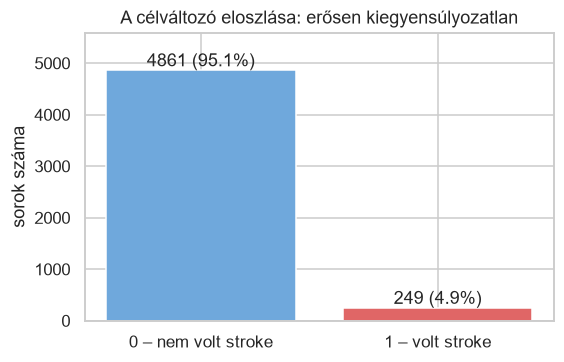

In [4]:
counts = raw[TARGET].value_counts().sort_index()
print(f"stroke = 1: {counts[1]} sor ({raw[TARGET].mean():.2%})   |   stroke = 0: {counts[0]} sor")

fig, ax = plt.subplots(figsize=(5.5, 3.4))
ax.bar(["0 – nem volt stroke", "1 – volt stroke"], counts.values, color=["#6fa8dc", "#e06666"])
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v} ({v / len(raw):.1%})", ha="center", va="bottom")
ax.set_ylabel("sorok száma"); ax.set_ylim(0, counts.max() * 1.15)
ax.set_title("A célváltozó eloszlása: erősen kiegyensúlyozatlan")
save_fig(fig, "01_celvaltozo")


**Megfigyelések:**
- 249 páciensnél (4,87%) fordult elő stroke, az adat tehát erősen kiegyensúlyozatlan (kb. 1 : 19).
- Egy mindig „nincs stroke”-ot mondó modell accuracyje 95,1% lenne, miközben egyetlen beteget sem találna meg. Az accuracy ezért itt félrevezető; helyette ROC-AUC-t, PR-AUC-t és recallt használunk.
- A kevés pozitív eset miatt a felosztás és a keresztvalidáció is **rétegzett**: minden részben azonos a stroke-arány.
- A modellek `class_weight`-tel nagyobb súlyt adnak a ritka osztály hibáinak, így a 0,5-ös küszöbbel is jeleznek stroke-ot.

### 2.2 Numerikus oszlopok: leíró statisztika, eloszlás, outlierek

Kiugrónak itt az IQR-szabály szerinti értékeket tekintjük: $x < Q_1 - 1{,}5\cdot IQR$ vagy $x > Q_3 + 1{,}5\cdot IQR$.

,count,mean,std,min,25%,50%,75%,max,ferdeség,IQR-kiugró (db)
age,5110.0,43.227,22.613,0.08,25.000,45.000,61.00,82.00,-0.137,0
avg_glucose_level,5110.0,106.148,45.284,55.12,77.245,91.885,114.09,271.74,1.572,627
bmi,4909.0,28.893,7.854,10.30,23.500,28.100,33.10,97.60,1.055,110


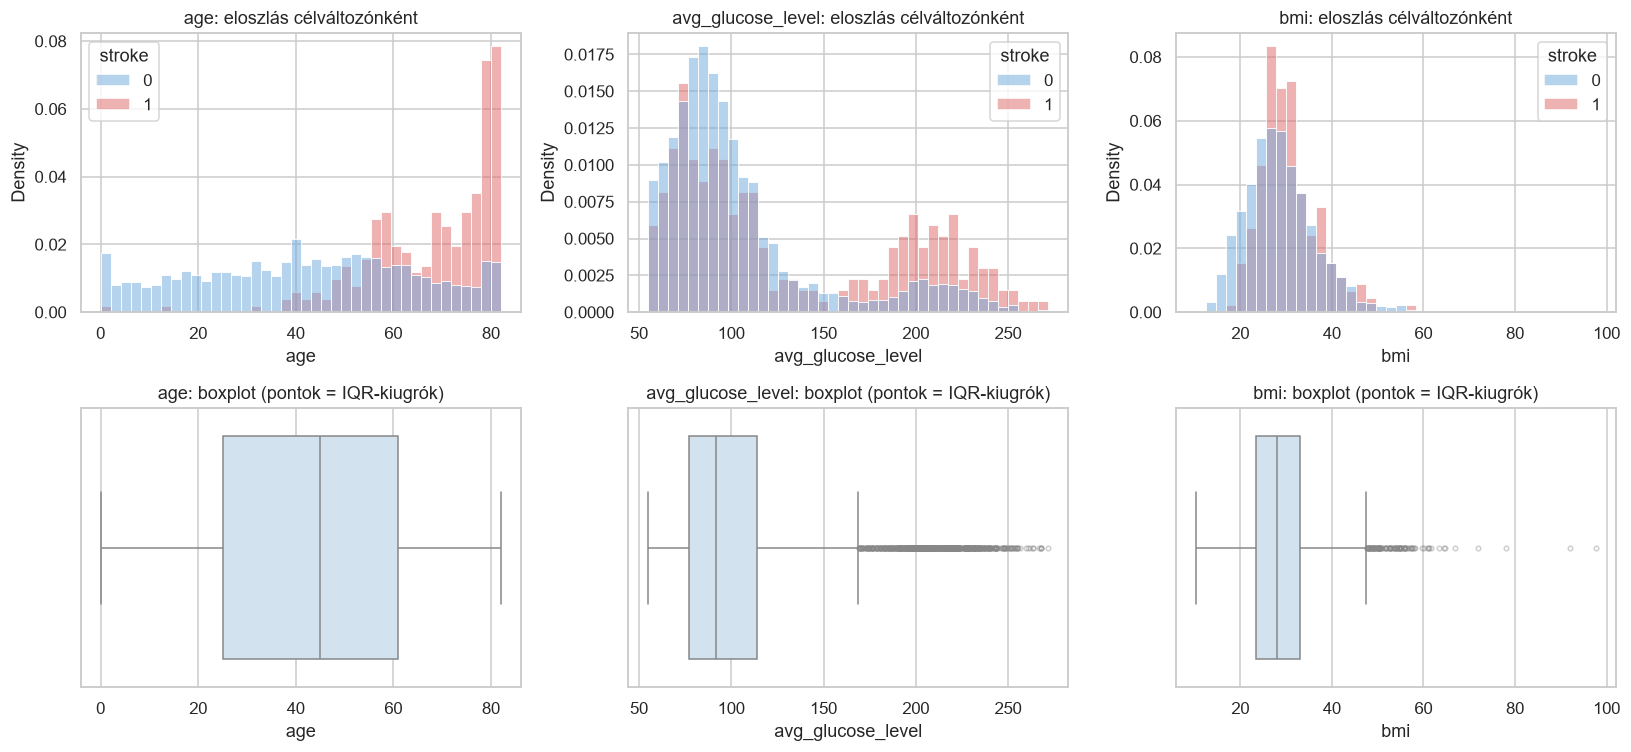

In [5]:
NUM_RAW = ["age", "avg_glucose_level", "bmi"]


def iqr_outlier_mask(s: pd.Series, k: float = 1.5) -> pd.Series:
    """True where the value lies outside [Q1 - k*IQR, Q3 + k*IQR] (Tukey's rule)."""
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)


desc = raw[NUM_RAW].describe().T
desc["ferdeség"] = raw[NUM_RAW].skew()
desc["IQR-kiugró (db)"] = [iqr_outlier_mask(raw[c].dropna()).sum() for c in NUM_RAW]
display(desc)

fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for j, col in enumerate(NUM_RAW):
    sns.histplot(data=raw, x=col, hue=TARGET, stat="density", common_norm=False, bins=40,
                 palette=["#6fa8dc", "#e06666"], ax=ax[0, j])
    ax[0, j].set_title(f"{col}: eloszlás célváltozónként")
    sns.boxplot(data=raw, x=col, ax=ax[1, j], color="#cfe2f3", flierprops={"marker": ".", "alpha": 0.4})
    ax[1, j].set_title(f"{col}: boxplot (pontok = IQR-kiugrók)")
plt.tight_layout()
save_fig(fig, "02_numerikus_eloszlasok")


**Megfigyelések:**
- Az `avg_glucose_level` (ferdeség 1,57) és a `bmi` (1,06) jobbra ferde, az `age` közel szimmetrikus (−0,14).
- A vércukorszint **kétcsúcsú**: a nagyobb csúcs kb. 70–110 mg/dL között, egy kisebb kb. 200 mg/dL körül van. A 627 IQR-kiugró ezért nem mérési hiba, hanem valószínűleg a cukorbetegek csoportja. Orvosilag is fontos csoport: 150 mg/dL felett 12,3% a stroke-arány, alatta 3,6%.
- A BMI 110 kiugrójának többsége elképzelhető érték (súlyos elhízás). A 60 feletti 13 érték (a maximum 97,6) viszont szélsőséges, és valószínűleg részben rögzítési hiba.
- A hisztogramokon az `age` választja szét legjobban a két osztályt: a 249 stroke-os páciensből 241 legalább 40 éves. A vércukornál a magas értékeknél nagyobb a stroke-osok aránya, a BMI-nél alig látszik eltérés.

*Döntés (a 4. fejezetben megvalósítva):* a kiugrókat nem töröljük; a numerikus oszlopokat az 1. és 99. percentilisre vágjuk (`QuantileClipper`), a vércukorszintet pedig logaritmizáljuk (`glucose_log`).

### 2.3 Kategorikus és bináris oszlopok

db  arány %  stroke-arány %
oszlop         kategória                                     
gender         Female           2994     58.6             4.7
               Male             2115     41.4             5.1
               Other               1      0.0             0.0
ever_married   No               1757     34.4             1.7
               Yes              3353     65.6             6.6
work_type      Govt_job          657     12.9             5.0
               Never_worked       22      0.4             0.0
               Private          2925     57.2             5.1
               Self-employed     819     16.0             7.9
               children          687     13.4             0.3
Residence_type Rural            2514     49.2             4.5
               Urban            2596     50.8             5.2
smoking_status Unknown          1544     30.2             3.0
               formerly smoked   885     17.3             7.9
               never smoked     1892     37.0             4.8
               smokes            789     15.4             5.3
hypertension   0                4612     90.3             4.0
               1                 498      9.7            13.3
heart_disease  0                4834     94.6             4.2
               1                 276      5.4            17.0

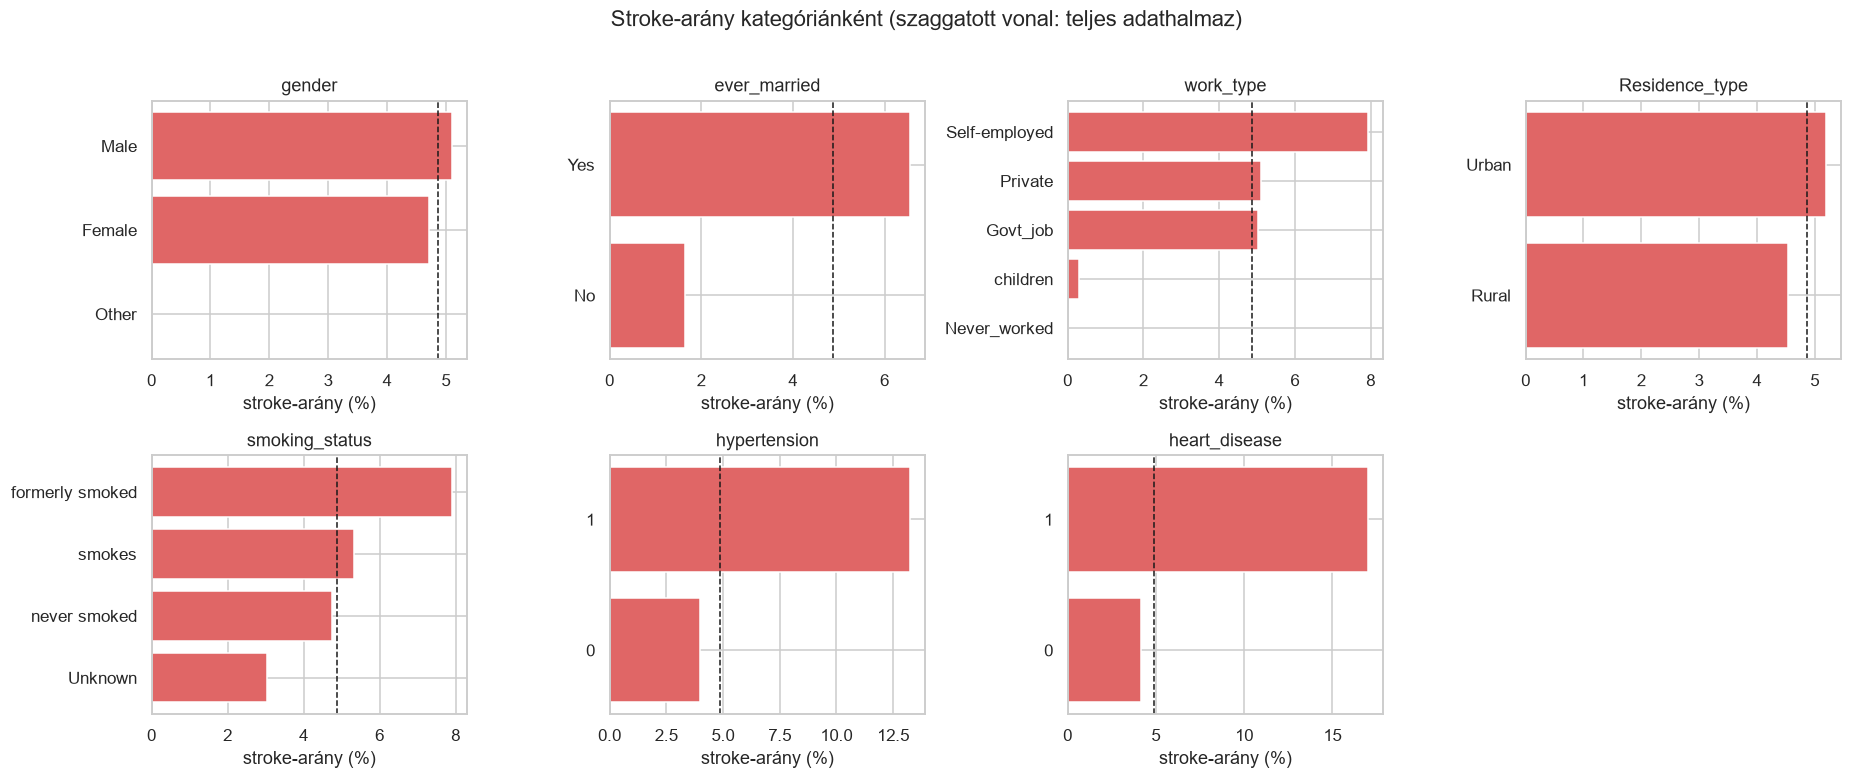

In [6]:
CAT_RAW = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]
BIN_RAW = ["hypertension", "heart_disease"]
overall_rate = raw[TARGET].mean()

rows = []
for col in CAT_RAW + BIN_RAW:
    grp = raw.groupby(col)[TARGET].agg(["size", "mean"])
    for cat, r in grp.iterrows():
        rows.append({"oszlop": col, "kategória": cat, "db": int(r["size"]),
                     "arány %": 100 * r["size"] / len(raw), "stroke-arány %": 100 * r["mean"]})
cat_table = pd.DataFrame(rows).set_index(["oszlop", "kategória"])
display(cat_table.round(1))

fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, col in zip(axes.ravel(), CAT_RAW + BIN_RAW):
    rate = raw.groupby(col)[TARGET].mean().sort_values() * 100
    ax.barh(rate.index.astype(str), rate.values, color="#e06666")
    ax.axvline(overall_rate * 100, color="k", ls="--", lw=1)
    ax.set_title(col); ax.set_xlabel("stroke-arány (%)")
axes.ravel()[-1].axis("off")
fig.suptitle("Stroke-arány kategóriánként (szaggatott vonal: teljes adathalmaz)", y=1.01)
plt.tight_layout()
save_fig(fig, "03_kategoriak")


**Megfigyelések:**
- A legnagyobb eltérést a két bináris kockázati tényező mutatja: magas vérnyomásnál 13,3% a stroke-arány (nélküle 4,0%), szívbetegségnél 17,0% (nélküle 4,2%).
- `work_type`: a `children` csoportban szinte nincs stroke (0,3%), a `Self-employed` csoportban 7,9%. A `smoking_status`-nál a `formerly smoked` a legmagasabb (7,9%), az `Unknown` a legalacsonyabb (3,0%).
- A `gender` (férfi 5,1%, nő 4,7%) és a `Residence_type` (városi 5,2%, vidéki 4,5%) szerint alig van különbség, ezektől kevés hatást várunk.
- **Ritka kategóriák:** a `gender = Other` egyetlen sorából nem lehet sem tanulni, sem mérni, ezért eldobjuk. A `Never_worked` 22 sorában nincs stroke; ezt a One-Hot kódoló egy közös „infrequent” oszlopba teszi.
- Az `ever_married = Yes` csoportban 6,6%, a `No` csoportban 1,7% a stroke-arány. Ez nem a házasság hatása: a házasok jellemzően idősebbek (a 2.5 fejezetben az `age` és az `ever_married` Spearman-korrelációja 0,66). A különbség mögött tehát elsősorban az életkor áll, amely itt **zavaró változó**.

### 2.4 Hiányzó értékek: MCAR, MAR vagy MNAR?

Két rejtett hiány van az adatban: a `bmi` „N/A” értékei, és a `smoking_status = Unknown` kategória.

,sorok,stroke-arány %,átlagéletkor
bmi,,,
a BMI ismert,4909,4.26,42.87
a BMI hiányzik,201,19.90,52.05


Függ-e a BMI hiánya a stroke-tól? χ²-próba: χ² = 98.6, p = 3.1e-23


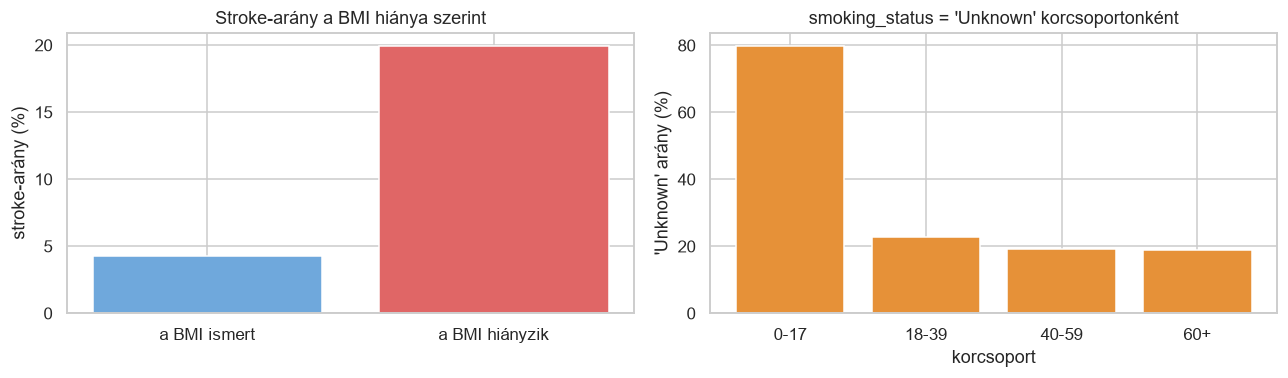

In [7]:
bmi_missing = raw["bmi"].isna()
miss_table = pd.DataFrame({
    "sorok": raw.groupby(bmi_missing)[TARGET].size(),
    "stroke-arány %": raw.groupby(bmi_missing)[TARGET].mean() * 100,
    "átlagéletkor": raw.groupby(bmi_missing)["age"].mean(),
}).rename(index={False: "a BMI ismert", True: "a BMI hiányzik"})
display(miss_table.round(2))

chi2, p_value, _, _ = stats.chi2_contingency(pd.crosstab(bmi_missing, raw[TARGET]))
print(f"Függ-e a BMI hiánya a stroke-tól? χ²-próba: χ² = {chi2:.1f}, p = {p_value:.2g}")

age_band = pd.cut(raw["age"], [0, 18, 40, 60, np.inf], right=False, labels=["0-17", "18-39", "40-59", "60+"])
unknown_share = (raw["smoking_status"] == "Unknown").groupby(age_band, observed=True).mean() * 100

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].bar(miss_table.index, miss_table["stroke-arány %"], color=["#6fa8dc", "#e06666"])
ax[0].set_ylabel("stroke-arány (%)"); ax[0].set_title("Stroke-arány a BMI hiánya szerint")
ax[1].bar(unknown_share.index.astype(str), unknown_share.values, color="#e69138")
ax[1].set_xlabel("korcsoport"); ax[1].set_ylabel("'Unknown' arány (%)")
ax[1].set_title("smoking_status = 'Unknown' korcsoportonként")
plt.tight_layout()
save_fig(fig, "04_hianyzo_ertekek")


**Megfigyelések:**
- **A BMI hiánya nem MCAR.** Ahol hiányzik, 19,9% a stroke-arány, ahol megvan, 4,3%. A χ²-próba szerint ez a különbség nem a véletlen műve (χ² = 98,6, p ≈ 3·10⁻²³). A hiányzó csoport átlagéletkora is magasabb (52,1 vs. 42,9 év).
- A hiány tehát megfigyelt változókkal (kor, stroke) függ össze, ezért legalább **MAR**. Hogy MNAR-e, vagyis magától a BMI értékétől függ-e, az adatból nem dönthető el. Elképzelhető például, hogy a stroke miatt kórházba került betegeknél maradt el a mérés.
- **Következmény:** a hiány ténye maga is információ. Ezért a medián imputálás mellett a `bmi_category = unknown` kategóriával meg is őrizzük (4.1). Puszta imputálásnál ez az információ elveszne. Ha a hiányos sorokat törölnénk, a 249 stroke-os esetből 40-et veszítenénk el.
- **Az „Unknown” dohányzási státusz** a 0–17 évesek 79,7%-ánál fordul elő, a felnőtt korcsoportokban csak 19–23%-nál. Gyerekeknél érthető módon nem kérdezték meg vagy nem rögzítették. Ez is a kortól függő, szisztematikus hiány. Külön kategóriaként tartjuk meg: egy feltételezett értékkel (pl. „never smoked”) való pótlás torzítana, a kategória viszont információt hordoz a modell számára.

### 2.5 Összefüggések a célváltozóval és egymással

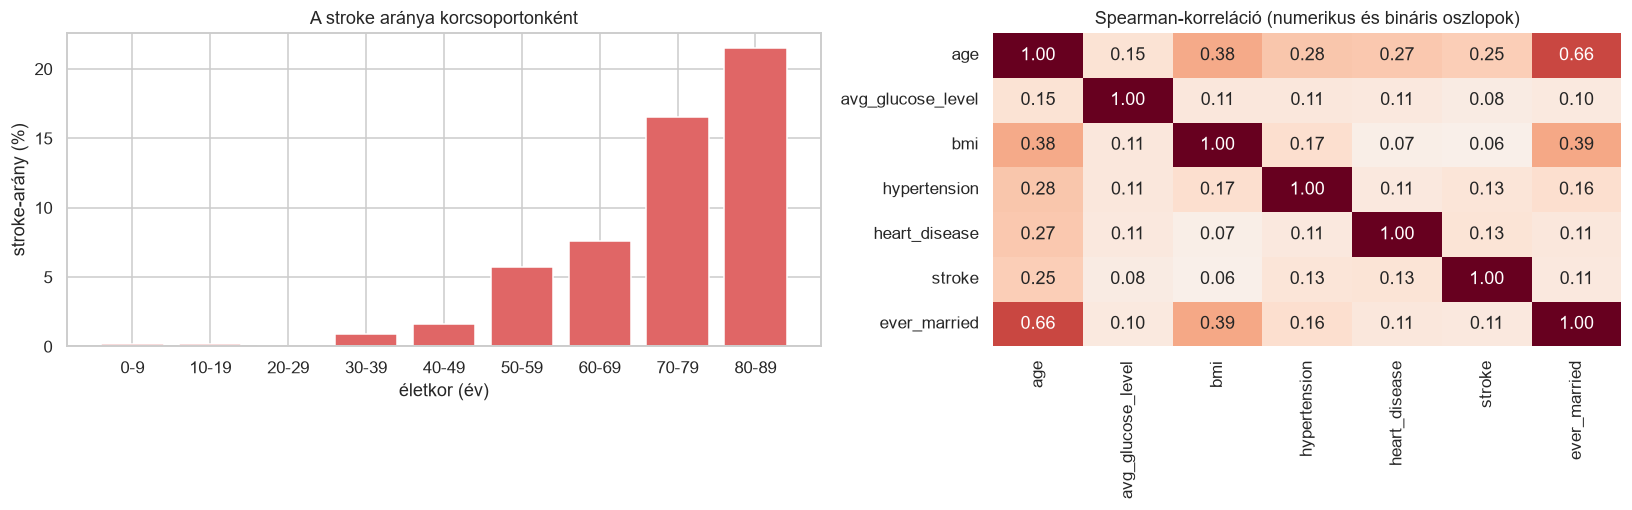

In [8]:
age_bins = pd.cut(raw["age"], bins=range(0, 91, 10), right=False)
age_rate = raw.groupby(age_bins, observed=True)[TARGET].agg(["mean", "size"])

corr_df = raw[NUM_RAW + BIN_RAW + [TARGET]].assign(ever_married=(raw["ever_married"] == "Yes").astype(int))
corr = corr_df.corr(method="spearman")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})
ax[0].bar([f"{int(b.left)}-{int(b.right) - 1}" for b in age_rate.index], age_rate["mean"] * 100, color="#e06666")
ax[0].set_xlabel("életkor (év)"); ax[0].set_ylabel("stroke-arány (%)")
ax[0].set_title("A stroke aránya korcsoportonként")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax[1], cbar=False)
ax[1].set_title("Spearman-korreláció (numerikus és bináris oszlopok)")
plt.tight_layout()
save_fig(fig, "05_osszefuggesek")


**Megfigyelések:**
- A stroke aránya **gyorsulva** nő a korral. 40 év alatt szinte nincs stroke (a 249 esetből 8), 50–59 évesen 5,8%, 70–79 évesen 16,5%, 80 felett 21,5% az arány. Ez nemlineáris összefüggés, amelyet a korcsoportok (`age_group`) a logisztikus regresszió számára is leírhatóvá tesznek.
- A `stroke`-kal az `age` korrelál a legerősebben (Spearman ρ = 0,25). Utána a `hypertension` és a `heart_disease` (0,13), majd a vércukor (0,08) és a BMI (0,06) következik. A ritka célváltozó miatt az egyenként gyenge korrelációk nem meglepők.
- A jellemzők egymással is korrelálnak: az `age` az `ever_married`-del (0,66), a `bmi`-vel (0,38), a `hypertension`-nel (0,28) és a `heart_disease`-zel (0,27). Az életkor tehát több más jellemző mögött is ott áll. Ez a 7. fejezetben a jellemzőfontosság értelmezését is befolyásolja.

### 2.6 Az EDA-döntések összefoglalása

| Megfigyelés | Döntés | Hol történik? |
|---|---|---|
| az `id` minden sorban egyedi | eldobjuk | felosztás előtt (3.) |
| `gender = Other`: 1 sor | eldobjuk (egy sorból nem lehet tanulni, és mérni sem) | felosztás előtt (3.) |
| duplikátum nincs | – (ellenőrizve) | felosztás előtt (3.) |
| a `bmi` 3,9%-a hiányzik, a hiány összefügg a stroke-kal | medián imputálás + `bmi_category = unknown` | Pipeline (4.) |
| a `smoking_status = Unknown` főleg gyerekeknél fordul elő | külön kategória marad | Pipeline (4.) |
| ferde `avg_glucose_level`, kiugró értékek | log-transzformáció + levágás az 1. és 99. percentilisnél | Pipeline (4.) |
| ritka kategória (`Never_worked`) | One-Hot `min_frequency=30`: „infrequent” csoportba kerül | Pipeline (4.) |
| 4,9% pozitív | rétegzett felosztás és CV, `class_weight="balanced"`, ROC-AUC és PR-AUC | 3., 5. |
| eltérő skálák | `StandardScaler` a logisztikus regressziónak (a fának nem kell) | Pipeline (4.) |

## 3. Adattisztítás és felosztás

A felosztás **előtt** csak olyan lépés történik, ami nem tanul az adatból (soronkénti művelet, sorok vagy oszlopok eldobása). Minden mást a Pipeline végez, a felosztás után.

**Rétegzett holdout (80/20):** a teszthalmaz stroke-aránya megegyezik a teljes adatéval. A teszthalmazt a 6. fejezetig **nem használjuk**: minden modellezési döntés (a jellemző-változatok és a hiperparaméterek kiválasztása) a tanítóhalmazon belüli keresztvalidáción születik.

In [9]:
df = raw.drop(columns="id")                                   # identifier: no information about stroke
n_other = int((df["gender"] == "Other").sum())
df = df[df["gender"] != "Other"].reset_index(drop=True)       # a single-row category cannot be learned or evaluated
n_dup = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print(f"Eldobva: 'id' oszlop, {n_other} sor gender = 'Other', {n_dup} duplikált sor  →  {df.shape[0]} sor marad")

X = df.drop(columns=TARGET)
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)      # stratified holdout: same stroke rate in both parts

print(f"tanítóhalmaz: {X_train.shape[0]} sor, ebből stroke {y_train.sum()} ({y_train.mean():.2%})")
print(f"teszthalmaz : {X_test.shape[0]} sor, ebből stroke {y_test.sum()} ({y_test.mean():.2%})  ← a végéig nem nyúlunk hozzá")


Eldobva: 'id' oszlop, 1 sor gender = 'Other', 0 duplikált sor  →  5109 sor marad
tanítóhalmaz: 4087 sor, ebből stroke 199 (4.87%)
teszthalmaz : 1022 sor, ebből stroke 50 (4.89%)  ← a végéig nem nyúlunk hozzá


## 4. Előfeldolgozás és feature engineering (1. és 2. lépés)

### 4.1 Saját transzformer-osztályok

| | `StrokeFeatureEngineer` | `QuantileClipper` |
|---|---|---|
| feladat | új jellemzők | outlierek levágása (winsorizálás) |
| tanul-e a `fit()`-ben? | **nem**: minden érték a saját sorából számolódik (**állapotmentes**) | **igen**: megtanulja az oszlopok 1. és 99. percentilisét (**állapotfüggő**) |
| mi lenne, ha a felosztás előtt futna? | nem okozna szivárgást | **szivárgás**: a percentilisekbe a teszt értékei is beleszólnának |

**Az új jellemzők és az indoklásuk:**
- `age_group`: a stroke kockázata nem lineárisan, hanem gyorsulva nő a korral (2.5). A korcsoportok ezt a lineáris modell számára is leírhatóvá teszik.
- `bmi_category`: a WHO-kategóriák orvosilag értelmezhetők, és a hiányzó BMI külön `unknown` kategóriát kap. Így a hiány ténye (2.4) információként megmarad.
- `glucose_log`: a vércukorszint erősen jobbra ferde (2.2). A logaritmus csökkenti a ferdeséget és a kiugrók súlyát.

In [10]:
class StrokeFeatureEngineer(BaseEstimator, TransformerMixin):
    """STATELESS feature engineering: every new value is computed from its own row only.

    New columns
        age_group     life stage: 0-17 / 18-39 / 40-59 / 60-74 / 75+ (stroke risk grows non-linearly with age)
        bmi_category  WHO categories (underweight / normal / overweight / obese); a missing BMI becomes
                      its own 'unknown' category, which keeps the information that the value was missing
        glucose_log   log(avg_glucose_level): reduces the strong right skew of the glucose values

    It learns nothing in fit(), so it could also run before the split; it sits in the Pipeline so that
    new data is always transformed in exactly the same way.
    """

    AGE_BINS = [0, 18, 40, 60, 75, np.inf]
    AGE_LABELS = ["0-17", "18-39", "40-59", "60-74", "75+"]
    BMI_BINS = [0, 18.5, 25, 30, np.inf]
    BMI_LABELS = ["underweight", "normal", "overweight", "obese"]

    NEW_COLUMNS = ["age_group", "bmi_category", "glucose_log"]

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)   # only the column names are remembered
        return self                                                    # nothing is learned from the values

    def transform(self, X):
        X = X.copy()
        X["age_group"] = pd.cut(X["age"], self.AGE_BINS, labels=self.AGE_LABELS, right=False).astype(str)
        bmi_cat = pd.cut(X["bmi"], self.BMI_BINS, labels=self.BMI_LABELS, right=False)
        X["bmi_category"] = bmi_cat.cat.add_categories("unknown").fillna("unknown").astype(str)
        X["glucose_log"] = np.log(X["avg_glucose_level"])
        return X

    def get_feature_names_out(self, input_features=None):
        names = self.feature_names_in_ if input_features is None else input_features
        return np.asarray(list(names) + self.NEW_COLUMNS, dtype=object)


class QuantileClipper(BaseEstimator, TransformerMixin):
    """STATEFUL outlier handling (winsorizing): learns the lower and upper quantile of every
    column in fit() and clips the values into that range in transform().

    Because the quantiles are learned from data, this step must live inside the Pipeline:
    in every CV round it learns them from the training folds only.
    """

    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.low_ = np.nanquantile(X, self.lower, axis=0)       # learned state (trailing _ = fitted attribute)
        self.high_ = np.nanquantile(X, self.upper, axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.low_, self.high_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


# quick check on three rows of the training set
StrokeFeatureEngineer().transform(X_train.head(3))[["age", "age_group", "bmi", "bmi_category",
                                                    "avg_glucose_level", "glucose_log"]]


,age,age_group,bmi,bmi_category,avg_glucose_level,glucose_log
845,48.0,40-59,33.1,obese,69.21,4.237
3744,29.0,18-39,21.2,normal,84.19,4.433
4183,35.0,18-39,22.9,normal,119.40,4.782


### 4.2 A Pipeline: előfeldolgozás és modell egyetlen objektumban

| Oszlopcsoport | Oszlopok | Lépések |
|---|---|---|
| numerikus | `age`, `glucose_log`, `bmi` | medián imputálás → levágás (1–99. percentilis) → `StandardScaler` (csak a logisztikus regressziónál) |
| bináris | `hypertension`, `heart_disease` | változatlanul (már 0/1) |
| kategorikus | `gender`, `ever_married`, `work_type`, `Residence_type`, `smoking_status`, `age_group`, `bmi_category` | One-Hot; a 30-nál ritkább kategóriák egy közös „infrequent” oszlopba kerülnek |

Az eredeti `avg_glucose_level` helyett a `glucose_log` kerül a modellbe.

**Miért fontos a Pipeline?** A `GridSearchCV` és a `cross_validate` minden foldban az **egész** Pipeline-t tanítja újra. Így a medián, a percentilisek, a skálázás átlaga és szórása, valamint a kategórialista mindig csak a tanító-foldokból számolódik. Ettől **szivárgásmentes** a keresztvalidáció.

In [11]:
# Columns after feature engineering, by type
NUM_FEATURES = ["age", "glucose_log", "bmi"]
BIN_FEATURES = ["hypertension", "heart_disease"]
CAT_FEATURES = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status",
                "age_group", "bmi_category"]
# Columns without feature engineering (used only in the comparison of the 2nd step)
NUM_RAW_FEATURES = ["age", "avg_glucose_level", "bmi"]
CAT_RAW_FEATURES = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]


def build_preprocessor(scale=True, num_cols=NUM_FEATURES, cat_cols=CAT_FEATURES):
    """Column-wise preprocessing. Every step learns ONLY in fit(), i.e. from the training folds."""
    num_steps = [("impute", SimpleImputer(strategy="median")),          # missing bmi → median of the training folds
                 ("clip", QuantileClipper(lower=0.01, upper=0.99))]     # outliers → clipped to the 1st / 99th percentile
    if scale:
        num_steps.append(("scale", StandardScaler()))                   # needed by logistic regression, not by trees
    return ColumnTransformer([
        ("num", Pipeline(num_steps), list(num_cols)),
        ("bin", "passthrough", BIN_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30,  # rare categories → 'infrequent'
                              sparse_output=False), list(cat_cols)),
    ], verbose_feature_names_out=False)


def build_pipeline(model, scale=True, extra_steps=(), feature_engineering=True):
    """Feature engineering → preprocessing → (optional selection / PCA) → model, in ONE object."""
    if feature_engineering:
        steps = [("features", StrokeFeatureEngineer()), ("prep", build_preprocessor(scale))]
    else:
        steps = [("prep", build_preprocessor(scale, NUM_RAW_FEATURES, CAT_RAW_FEATURES))]
    return Pipeline(steps + list(extra_steps) + [("model", model)])


example = build_pipeline(LogisticRegression(max_iter=5000, class_weight="balanced"))
Z = example[:-1].fit(X_train, y_train).transform(X_train)          # fitted on the TRAINING set only (inspection)
names = example[:-1].get_feature_names_out()
print(f"A modell bemenete az előfeldolgozás után: {Z.shape[1]} oszlop")
print(list(names))
example


A modell bemenete az előfeldolgozás után: 30 oszlop
['age', 'glucose_log', 'bmi', 'hypertension', 'heart_disease', 'gender_Female', 'gender_Male', 'ever_married_No', 'ever_married_Yes', 'work_type_Govt_job', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'work_type_infrequent_sklearn', 'Residence_type_Rural', 'Residence_type_Urban', 'smoking_status_Unknown', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes', 'age_group_0-17', 'age_group_18-39', 'age_group_40-59', 'age_group_60-74', 'age_group_75+', 'bmi_category_normal', 'bmi_category_obese', 'bmi_category_overweight', 'bmi_category_underweight', 'bmi_category_unknown']


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('bin', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature

### 4.3 Megérik-e az új jellemzők, a jellemzőkiválasztás és a PCA? (2. lépés)

Öt változatot hasonlítunk össze ugyanazzal a logisztikus regresszióval, 5-fold rétegzett CV-vel a **tanítóhalmazon**. A kiválasztás és a PCA is a Pipeline része, tehát foldonként tanul.
- **SelectKBest (MI):** filter módszer, a kölcsönös információ alapján a 10 legjobb oszlopot tartja meg.
- **L1-alapú kiválasztás:** embedded módszer; az L1-regularizált logisztikus regresszió nullára húzza a felesleges oszlopok súlyát.
- **PCA:** annyi főkomponenst tart meg, amennyi a variancia 95%-át magyarázza.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"roc_auc": "roc_auc", "pr_auc": "average_precision"}
lr = LogisticRegression(max_iter=5000, class_weight="balanced")
l1_selector = SelectFromModel(LogisticRegression(l1_ratio=1.0, solver="liblinear", C=0.1, class_weight="balanced"))
mi = partial(mutual_info_classif, random_state=SEED)

variants = {
    "A) nyers jellemzők (új jellemzők nélkül)": build_pipeline(lr, feature_engineering=False),
    "B) + új jellemzők": build_pipeline(lr),
    "C) + új jellemzők + SelectKBest (MI, k = 10)": build_pipeline(lr, extra_steps=[("select", SelectKBest(mi, k=10))]),
    "D) + új jellemzők + L1-alapú kiválasztás": build_pipeline(lr, extra_steps=[("select", l1_selector)]),
    "E) + új jellemzők + PCA (95% variancia)": build_pipeline(lr, extra_steps=[("pca", PCA(n_components=0.95))]),
}
rows = []
for name, pipe in variants.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)   # every step learns per fold
    rows.append({"változat": name,
                 "CV ROC-AUC": res["test_roc_auc"].mean(), "± szórás": res["test_roc_auc"].std(ddof=1),
                 "CV PR-AUC": res["test_pr_auc"].mean(), "± szórás ": res["test_pr_auc"].std(ddof=1)})
variant_table = pd.DataFrame(rows).set_index("változat")
variant_table


,CV ROC-AUC,± szórás,CV PR-AUC,± szórás
változat,,,,
A) nyers jellemzők (új jellemzők nélkül),0.839,0.022,0.191,0.049
B) + új jellemzők,0.849,0.031,0.217,0.040
"C) + új jellemzők + SelectKBest (MI, k = 10)",0.847,0.034,0.207,0.045
D) + új jellemzők + L1-alapú kiválasztás,0.851,0.027,0.222,0.039
E) + új jellemzők + PCA (95% variancia),0.836,0.022,0.182,0.031


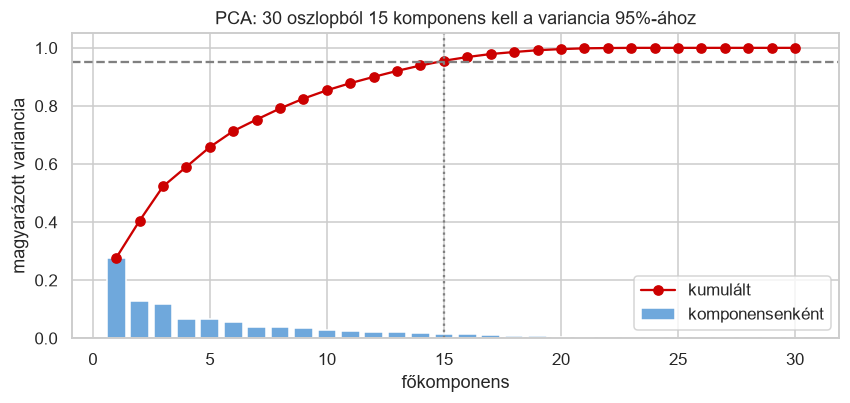

In [13]:
pca = PCA().fit(Z)      # Z: the preprocessed TRAINING set = exactly what the PCA of variant E receives
cum = np.cumsum(pca.explained_variance_ratio_)
k95 = int(np.argmax(cum >= 0.95) + 1)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(range(1, len(cum) + 1), pca.explained_variance_ratio_, color="#6fa8dc", label="komponensenként")
ax.plot(range(1, len(cum) + 1), cum, "o-", color="#cc0000", label="kumulált")
ax.axhline(0.95, ls="--", color="grey"); ax.axvline(k95, ls=":", color="grey")
ax.set_xlabel("főkomponens"); ax.set_ylabel("magyarázott variancia"); ax.legend()
ax.set_title(f"PCA: {Z.shape[1]} oszlopból {k95} komponens kell a variancia 95%-ához")
save_fig(fig, "06_pca_scree")


**Eredmények:**
- **Az új jellemzők javítottak (A → B):** a ROC-AUC 0,839-ről 0,849-re, a PR-AUC 0,191-ről 0,217-re nőtt. A javulás a fold-szórásnál (kb. 0,03) kisebb, de mindkét metrikában egy irányba mutat, és a jellemzők orvosilag is indokoltak.
- **A jellemzőkiválasztás nem hozott érdemi javulást.** A SelectKBest (C: 0,847) kicsit rontott. Az L1-alapú kiválasztás (D: 0,851) 0,002-vel jobb a B-nél, ez azonban a fold-szórás töredéke, tehát a zajon belül van.
- **A PCA rontott** (E: 0,836, PR-AUC 0,182). A 30 oszlopból 15 komponens kell a variancia 95%-ához, a dimenziót tehát csak a felére csökkenti. A PCA ráadásul nem látja a célváltozót: a legnagyobb variancia irányai nem esnek egybe a stroke-ot legjobban előrejelző irányokkal.

**Döntés:** a végleges modellek a **B) változatot** használják (új jellemzők, kiválasztás és PCA nélkül). Ha két változat különbsége a szóráson belül van, az egyszerűbbet választjuk. A D) nem kimutathatóan jobb a B)-nél, viszont egy újabb tanuló lépést hoz a Pipeline-ba. A PCA ellen szól az is, hogy a komponensek az összes oszlop keverékei, így elveszne a 7. fejezethez szükséges értelmezhetőség.

## 5. Modellezés és keresztvalidáció (3. lépés)

| Modell | Szerep | Hangolt hiperparaméterek |
|---|---|---|
| `DummyClassifier` (prior) | **alsó padló**: a tanulás nélküli jóslás szintje | – |
| **logisztikus regresszió** | **Baseline**: egyszerű, lineáris, értelmezhető | `C`: a regularizáció erőssége fordítva (kis C → erős büntetés) |
| **Random Forest** (300 fa) | **haladó modell**: nemlineáris összefüggések és interakciók | `max_depth`, `min_samples_leaf` (a túltanulás fékjei), `max_features` (a fák közötti korreláció csökkentése) |

**A beállítás:**
- `StratifiedKFold(n_splits=5, shuffle=True)`: minden foldban kb. 40 stroke-os eset van.
- **`GridSearchCV`**: minden jelöltet 5-fold CV-vel mér, a legjobb **átlagos** validációs ROC-AUC nyer, majd **refit** következik a teljes tanítóhalmazon.
- **`class_weight="balanced"`**: a ritka stroke-osztály hibái nagyobb súlyt kapnak, így a 0,5-ös küszöb is értelmes jóslatokat ad.

In [14]:
MODELS = {
    "Dummy (alsó padló)": (
        build_pipeline(DummyClassifier(strategy="prior")), {}),
    "Baseline: logisztikus regresszió": (
        build_pipeline(LogisticRegression(max_iter=5000, class_weight="balanced")),
        {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3]}),
    "Haladó: Random Forest": (
        build_pipeline(RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                              random_state=SEED, n_jobs=-1), scale=False),
        {"model__max_depth": [4, 8, None], "model__min_samples_leaf": [5, 20, 50],
         "model__max_features": ["sqrt", 0.5]}),
}

searches = {}
for name, (pipe, grid) in MODELS.items():
    t0 = time.time()
    gs = GridSearchCV(pipe, grid, cv=cv, scoring=SCORING, refit="roc_auc", n_jobs=-1)   # refit: on the whole training set
    searches[name] = gs.fit(X_train, y_train)
    n_cand = len(gs.cv_results_["params"])
    print(f"{name:34s} {n_cand:2d} jelölt × {cv.n_splits} fold = {n_cand * cv.n_splits:3d} tanítás + 1 refit  ({time.time() - t0:.0f} s)")


Dummy (alsó padló)                  1 jelölt × 5 fold =   5 tanítás + 1 refit  (0 s)
Baseline: logisztikus regresszió    6 jelölt × 5 fold =  30 tanítás + 1 refit  (1 s)
Haladó: Random Forest              18 jelölt × 5 fold =  90 tanítás + 1 refit  (37 s)


modell,Dummy (alsó padló),Baseline: logisztikus regresszió,Haladó: Random Forest
ROC-AUC átlag,0.500,0.851,0.846
ROC-AUC fold-szórás,0.000,0.026,0.029
ROC-AUC SE,0.000,0.011,0.013
ROC-AUC 95% CI alsó,0.500,0.820,0.810
ROC-AUC 95% CI felső,0.500,0.883,0.882
PR-AUC átlag,0.049,0.219,0.208


Dummy (alsó padló)                 legjobb: {}
Baseline: logisztikus regresszió   legjobb: {'model__C': 0.1}
Haladó: Random Forest              legjobb: {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 20}


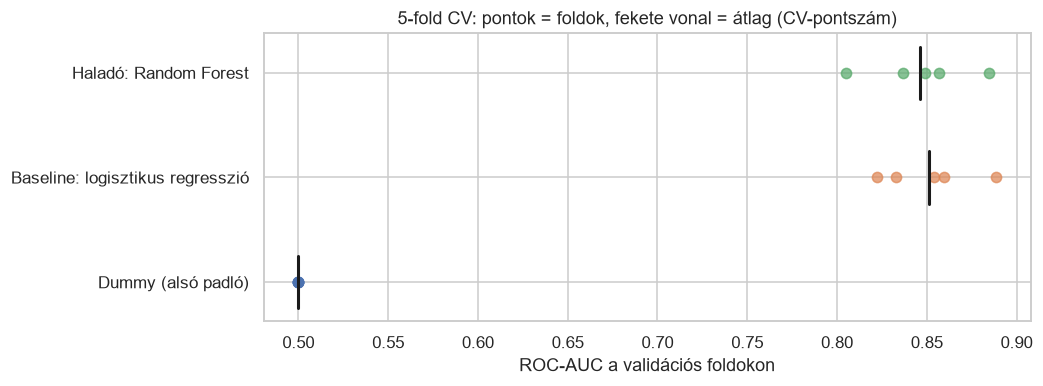

In [15]:
def cv_summary(gs, metric="roc_auc"):
    """Mean, standard deviation, SE and t-based 95% CI of the best candidate's fold scores."""
    i, k = gs.best_index_, cv.n_splits
    folds = np.array([gs.cv_results_[f"split{j}_test_{metric}"][i] for j in range(k)])
    se = folds.std(ddof=1) / np.sqrt(k)
    half = stats.t.ppf(0.975, df=k - 1) * se
    return folds, {"átlag": folds.mean(), "fold-szórás": folds.std(ddof=1), "SE": se,
                   "95% CI alsó": folds.mean() - half, "95% CI felső": folds.mean() + half}


rows, fold_scores = [], {}
for name, gs in searches.items():
    folds, s = cv_summary(gs, "roc_auc")
    fold_scores[name] = folds
    _, s_pr = cv_summary(gs, "pr_auc")
    rows.append({"modell": name, **{f"ROC-AUC {k}": v for k, v in s.items()},
                 "PR-AUC átlag": s_pr["átlag"], "legjobb hiperparaméterek": gs.best_params_})
cv_table = pd.DataFrame(rows).set_index("modell")
display(cv_table.drop(columns="legjobb hiperparaméterek").T.round(4))      # transposed: fits the PDF page
for name, gs in searches.items():
    print(f"{name:34s} legjobb: {gs.best_params_}")

fig, ax = plt.subplots(figsize=(9, 3.4))
for i, (name, folds) in enumerate(fold_scores.items()):
    ax.scatter(folds, [i] * len(folds), s=45, alpha=0.7)
    ax.plot([folds.mean()] * 2, [i - 0.25, i + 0.25], color="k", lw=2)
ax.set_yticks(range(len(fold_scores)), list(fold_scores)); ax.set_xlabel("ROC-AUC a validációs foldokon")
ax.set_title("5-fold CV: pontok = foldok, fekete vonal = átlag (CV-pontszám)")
save_fig(fig, "07_cv_foldok")


**Megfigyelések:**
- Mindkét modell messze a Dummy fölött van. A ROC-AUC 0,5-ről kb. 0,85-re nő, a PR-AUC 0,049-ről 0,22-re (LR), ill. 0,21-re (RF), ami a véletlen szint kb. négyszerese.
- A Baseline (0,851 ± 0,026) és a Random Forest (0,846 ± 0,029) különbsége 0,005, ez a fold-szórás ötöde. A CV-alapú CI-k ([0,820; 0,883] és [0,810; 0,882]) szinte teljesen átfednek. A haladó modell tehát nem nyújt kimutatható előnyt.
- **Nyertes hiperparaméterek:**
  - Logisztikus regresszió: `C = 0,1`, azaz közepesen erős regularizáció.
  - Random Forest: a fák mélysége nincs korlátozva (`max_depth = None`), de a `min_samples_leaf = 20` miatt minden levélben legalább 20 minta van. Ez erős regularizáció: a 4 087 soros, 199 stroke-os tanítóhalmazon megakadályozza, hogy a fák egyes pácienseket „megjegyezzenek”. A `max_features = "sqrt"` a fák közötti korrelációt csökkenti.
- Az, hogy a nemlineáris modell nem jobb, arra utal, hogy a jel nagy része az életkor monoton hatása. Ezt a korcsoportokkal kiegészített lineáris modell is jól leírja.

**Megjegyzés a CV-alapú CI-hez:** a $\bar s \pm t_{0{,}975;4}\cdot s/\sqrt{5}$ intervallum **túl szűk** lehet, mert a foldok tanítóhalmazai átfednek. A legjobb jelölt CV-pontszáma ráadásul optimista. A következtetés ezért a 6. fejezet teszt-bootstrapjére és statisztikai próbájára épül.

## 6. Teljesítményértékelés és statisztikai teszt (4. lépés)

### 6.1 Metrikák a teszthalmazon (egyszer!)

A refit után a végleges modellek most látják először a teszthalmazt.

| Metrika | Mit mér | Véletlen szint |
|---|---|---|
| ROC-AUC | rangsorolás, küszöbfüggetlen | 0,5 |
| PR-AUC (AP) | precision–recall egyensúly; kiegyensúlyozatlan adatra | a pozitív arány (≈ 0,049) |
| recall (szenzitivitás) | a stroke-osok hány %-át találja meg: $TP/(TP+FN)$ | – |
| specificitás | az egészségesek hány %-át ismeri fel: $TN/(TN+FP)$ | – |
| precision | a riasztások hány %-a jogos: $TP/(TP+FP)$ | – |
| F1, MCC, balanced accuracy | egy számban összegzik a tévesztési mátrixot | – |
| Brier | a jósolt valószínűségek pontossága (kisebb = jobb) | – |

In [16]:
BASE, ADV = "Baseline: logisztikus regresszió", "Haladó: Random Forest"
final = {name: gs.best_estimator_ for name, gs in searches.items()}       # refitted on the whole training set
proba = {name: m.predict_proba(X_test)[:, 1] for name, m in final.items()}  # the test set is used here, ONCE
pred = {name: m.predict(X_test) for name, m in final.items()}               # threshold 0.5


def classification_report_row(y_true, p, yhat):
    tn, fp, fn, tp = confusion_matrix(y_true, yhat).ravel()
    return {"ROC-AUC": roc_auc_score(y_true, p), "PR-AUC (AP)": average_precision_score(y_true, p),
            "recall (szenzitivitás)": recall_score(y_true, yhat), "specificitás": tn / (tn + fp),
            "precision": precision_score(y_true, yhat, zero_division=0), "F1": f1_score(y_true, yhat),
            "MCC": matthews_corrcoef(y_true, yhat), "balanced accuracy": balanced_accuracy_score(y_true, yhat),
            "Brier": brier_score_loss(y_true, p), "TP": tp, "FP": fp, "FN": fn, "TN": tn}


test_table = pd.DataFrame({name: classification_report_row(y_test, proba[name], pred[name]) for name in final}).T
print(f"Véletlen szint: ROC-AUC = 0,5;  PR-AUC = a pozitív arány = {y_test.mean():.3f}")
test_table.T.round(3)          # transposed: metrics in rows, models in columns


Véletlen szint: ROC-AUC = 0,5;  PR-AUC = a pozitív arány = 0.049


,Dummy (alsó padló),Baseline: logisztikus regresszió,Haladó: Random Forest
ROC-AUC,0.500,0.835,0.833
PR-AUC (AP),0.049,0.230,0.237
recall (szenzitivitás),0.000,0.840,0.760
specificitás,1.000,0.740,0.811
precision,0.000,0.142,0.171
F1,0.000,0.243,0.279
MCC,0.000,0.276,0.299
balanced accuracy,0.500,0.790,0.785
Brier,0.047,0.169,0.123
TP,0.000,42.000,38.000


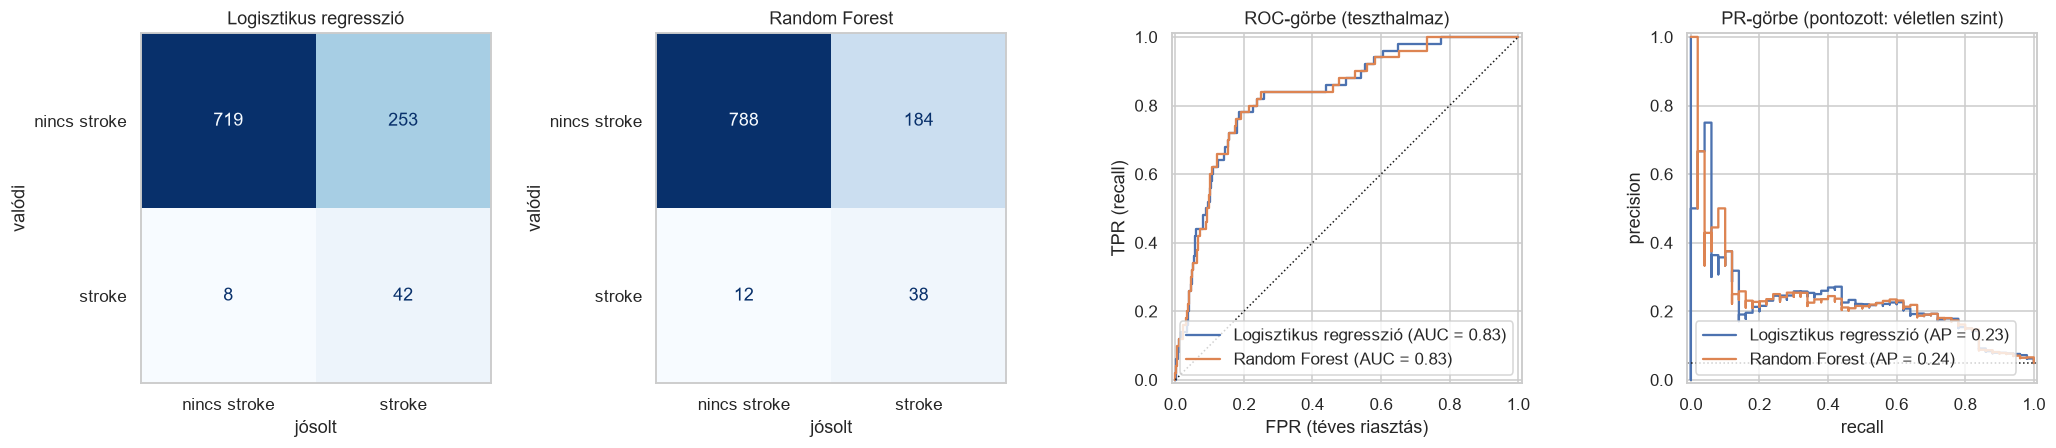

In [17]:
short = {BASE: "Logisztikus regresszió", ADV: "Random Forest"}
fig, ax = plt.subplots(1, 4, figsize=(19, 4.2))
for k, name in enumerate([BASE, ADV]):
    ConfusionMatrixDisplay.from_predictions(y_test, pred[name], ax=ax[k], colorbar=False, cmap="Blues",
                                            display_labels=["nincs stroke", "stroke"])
    ax[k].set_title(short[name]); ax[k].set_xlabel("jósolt"); ax[k].set_ylabel("valódi"); ax[k].grid(False)
for name in [BASE, ADV]:
    RocCurveDisplay.from_predictions(y_test, proba[name], ax=ax[2], name=short[name])
    PrecisionRecallDisplay.from_predictions(y_test, proba[name], ax=ax[3], name=short[name])
ax[2].plot([0, 1], [0, 1], "k:", lw=1); ax[2].set_title("ROC-görbe (teszthalmaz)")
ax[2].set_xlabel("FPR (téves riasztás)"); ax[2].set_ylabel("TPR (recall)")
ax[3].axhline(y_test.mean(), color="k", ls=":", lw=1); ax[3].set_title("PR-görbe (pontozott: véletlen szint)")
ax[3].set_xlabel("recall"); ax[3].set_ylabel("precision")
plt.tight_layout()
save_fig(fig, "08_teszt_eredmenyek")


**Megfigyelések:**
- A teszt ROC-AUC (LR 0,835, RF 0,833) kicsit alacsonyabb a CV-pontszámnál (0,851, ill. 0,846). Ez várható: a legjobb jelölt CV-pontszáma optimista, az 50 pozitív esetes teszthalmaz eredménye pedig zajos. Túltanulásra utaló nagy esés nincs.
- **Eltérő hibaprofil a 0,5-ös küszöbnél:**
  - A logisztikus regresszió több stroke-ot talál meg (recall 0,84: 42 / 50, FN = 8), de több téves riasztást ad (FP = 253, specificitás 0,74).
  - A Random Forest óvatosabb: kevesebb a téves riasztása (FP = 184, specificitás 0,81), de több stroke-ot hagy ki (FN = 12, recall 0,76).
  - Orvosi szűrésnél a kimaradt stroke a drágább hiba, ez a logisztikus regresszió mellett szól. A különbség azonban **küszöbkérdés**, nem a modellek rangsoroló képességéé.
- Mindkét modell precisionje alacsony (0,14 és 0,17), azaz a riasztások 83–86%-a téves. 4,9%-os pozitív arány mellett ez természetes: a magas kockázatú csoportba is sokkal több egészséges kerül, mint beteg. A precision így is a véletlen szint (0,049) 3–3,5-szerese, a PR-AUC (0,23–0,24) pedig közel ötszöröse.
- A Dummy accuracyje 972 / 1 022 = 95,1% lenne. A két modellé ennél alacsonyabb (LR 74,5%, RF 80,8%), mégis hasznosabbak, mert a Dummy egyetlen beteget sem talál meg (recall = 0).
- A Brier-pontszám (LR 0,169, RF 0,123) rosszabb a Dummyénál (0,047). Ennek oka a `class_weight`: a súlyozás felfelé torzítja a jósolt valószínűségeket. Ezek rangsorolásra jók, de valószínűségként nem értelmezhetők (**nem kalibráltak**).

### 6.2 Konfidenciaintervallumok: páros bootstrap a teszthalmazon

**Az eljárás (percentilis bootstrap):**
1. A teszthalmaz $N$ sorából $N$-et húzunk **visszatevéssel**.
2. Ezen a mintán kiszámoljuk mindkét modell metrikáját és a **különbségüket**.
3. Ezt 2000-szer megismételjük.
4. A 95% CI a 2000 érték **2,5. és 97,5. percentilise**.

**Páros:** ugyanazok a sorok kerülnek mindkét modellhez, így a különbség CI-je pontosabb, mint két külön CI összevetése. Ha a különbség CI-je tartalmazza a 0-t, a teszthalmaz alapján nem mondható, hogy az egyik modell jobb.

,Random Forest,Logisztikus regresszió,különbség (RF − LR),P(Δ* ≤ 0)
metrika,,,,
ROC-AUC,0.833 [0.773; 0.889],0.835 [0.776; 0.889],-0.002 [-0.018; +0.016],0.578
PR-AUC (AP),0.237 [0.154; 0.356],0.230 [0.151; 0.353],+0.007 [-0.061; +0.060],0.457


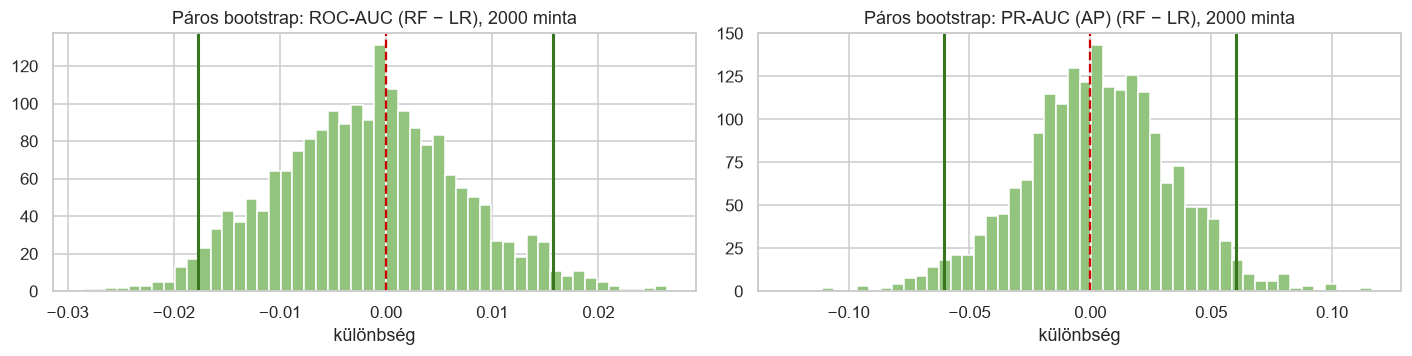

In [18]:
def paired_bootstrap_ci(y_true, p_a, p_b, metric, n_boot=2000, seed=SEED, alpha=0.05):
    """Percentile bootstrap CI for two models and for their difference (A − B).
    PAIRED: every resample uses the same rows for both models."""
    y_true, p_a, p_b = np.asarray(y_true), np.asarray(p_a), np.asarray(p_b)
    rng = np.random.default_rng(seed)
    a, b = np.empty(n_boot), np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))       # draw N rows WITH replacement
        while y_true[idx].min() == y_true[idx].max():         # AUC needs both classes in the sample
            idx = rng.integers(0, len(y_true), len(y_true))
        a[i], b[i] = metric(y_true[idx], p_a[idx]), metric(y_true[idx], p_b[idx])
    q = [100 * alpha / 2, 100 * (1 - alpha / 2)]
    return {"A": np.percentile(a, q), "B": np.percentile(b, q), "diff": np.percentile(a - b, q),
            "diff_samples": a - b, "p_le_0": float(np.mean(a - b <= 0))}


rows, boot = [], {}
for mname, metric in [("ROC-AUC", roc_auc_score), ("PR-AUC (AP)", average_precision_score)]:
    bs = paired_bootstrap_ci(y_test, proba[ADV], proba[BASE], metric)
    boot[mname] = bs
    point_a, point_b = metric(y_test, proba[ADV]), metric(y_test, proba[BASE])
    rows.append({"metrika": mname,
                 "Random Forest": f"{point_a:.3f} [{bs['A'][0]:.3f}; {bs['A'][1]:.3f}]",
                 "Logisztikus regresszió": f"{point_b:.3f} [{bs['B'][0]:.3f}; {bs['B'][1]:.3f}]",
                 "különbség (RF − LR)": f"{point_a - point_b:+.3f} [{bs['diff'][0]:+.3f}; {bs['diff'][1]:+.3f}]",
                 "P(Δ* ≤ 0)": round(bs["p_le_0"], 3)})
display(pd.DataFrame(rows).set_index("metrika"))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
for a_, mname in zip(ax, boot):
    d = boot[mname]["diff_samples"]
    a_.hist(d, bins=50, color="#93c47d", edgecolor="white")
    for v in boot[mname]["diff"]:
        a_.axvline(v, color="#38761d", lw=2)
    a_.axvline(0, color="#cc0000", ls="--", lw=1.5)
    a_.set_title(f"Páros bootstrap: {mname} (RF − LR), 2000 minta"); a_.set_xlabel("különbség")
plt.tight_layout()
save_fig(fig, "09_bootstrap_kulonbseg")


**Megfigyelések:**
- **A CI-k szélesek.** A ROC-AUC-intervallumok kb. 0,11 szélesek (LR [0,776; 0,889], RF [0,773; 0,889]), a PR-AUC-intervallumok kb. 0,20 szélesek (LR [0,151; 0,353], RF [0,154; 0,356]). Ennek fő oka, hogy a teszthalmazban csak 50 stroke-os eset van, így már néhány beteg rangsorbeli helye is érezhetően elmozdítja a metrikát.
- **A különbség CI-je mindkét metrikánál tartalmazza a 0-t:** ROC-AUC (RF − LR) −0,002 [−0,018; +0,016], PR-AUC +0,007 [−0,061; +0,060].
- A páros CI jóval szűkebb, mint az egyes modellek CI-je, mert a két modell jóslatai erősen összefüggenek: nagyrészt ugyanazokat a pácienseket tartják kockázatosnak.
- A `P(Δ* ≤ 0)` azt mutatja, hogy a bootstrap-minták hányad részében nem volt jobb a Random Forest. Ez ROC-AUC-nál 0,578, PR-AUC-nál 0,457. Mindkettő közel van a 0,5-höz, vagyis a minták kb. felében az egyik, felében a másik modell nyer. A teszthalmaz alapján tehát nem mondható, hogy az egyik modell jobb.

### 6.3 Statisztikai próba: 5×2cv t- és F-próba

**Miért nem sima páros t-próba a 10-fold pontszámain?** A foldok tanítóhalmazai kb. 90%-ban átfednek. A pontszámok ezért nem függetlenek, a szórás alulbecsült, és a próba túl gyakran jelez hamis különbséget.

**Az 5×2cv** ötször kettévágja a **tanítóhalmazt**, és mindkét irányban tanít és mér. A két fél között nincs átfedés. Mindkét modell **a hangolás után kapott legjobb beállítással** (a `best_estimator_` receptjével) tanul újra minden félen, a teszthalmazhoz nem nyúlunk.

- $H_0$: a két modell ROC-AUC-ja azonos. $H_1$: eltér (kétoldali próba, $\alpha = 0{,}05$).
- $p_i^{(j)}$ = pontszám$_{RF}$ − pontszám$_{LR}$ az $i$-edik ismétlés $j$-edik felén; $\bar p_i = (p_i^{(1)} + p_i^{(2)})/2$, $s_i^2 = (p_i^{(1)} - \bar p_i)^2 + (p_i^{(2)} - \bar p_i)^2$.
- **t-próba (Dietterich, 1998):** $t = p_1^{(1)} \big/ \sqrt{\tfrac15 \sum_i s_i^2} \sim t_5$, a kritikus érték 2,571.
- **Combined F-próba (Alpaydin, 1999):** $f = \sum_i \sum_j \big(p_i^{(j)}\big)^2 \big/ \big(2 \sum_i s_i^2\big) \sim F_{10,5}$, a kritikus érték 4,74. Mind a 10 különbséget felhasználja, ezért nagyobb az ereje.

In [19]:
def paired_5x2cv_test(estimator_a, estimator_b, X, y, scoring="roc_auc", seed=SEED):
    """Dietterich's 5x2cv paired t-test and Alpaydin's combined 5x2cv F-test.

    5 repetitions × 2-fold (stratified). In each half both models are trained from scratch
    (clone) on the other half; p[i, j] = score_A − score_B on the j-th half of the i-th repetition.
    """
    scorer = get_scorer(scoring)
    p = np.zeros((5, 2))
    for i in range(5):
        halves = StratifiedKFold(n_splits=2, shuffle=True, random_state=seed + i)   # new random split in every repetition
        for j, (tr, te) in enumerate(halves.split(X, y)):
            a = clone(estimator_a).fit(X.iloc[tr], y.iloc[tr])
            b = clone(estimator_b).fit(X.iloc[tr], y.iloc[tr])
            p[i, j] = scorer(a, X.iloc[te], y.iloc[te]) - scorer(b, X.iloc[te], y.iloc[te])
    p_mean = p.mean(axis=1)
    s2 = ((p - p_mean[:, None]) ** 2).sum(axis=1)                 # variance estimate of every repetition
    t = p[0, 0] / np.sqrt(s2.mean())                              # ~ t with 5 degrees of freedom
    f = (p ** 2).sum() / (2 * s2.sum())                           # ~ F(10, 5)
    return {"p": p, "t": t, "p_t": 2 * stats.t.sf(abs(t), df=5), "F": f, "p_F": stats.f.sf(f, 10, 5)}


test_rows, five_by_two = [], {}
for scoring, label in [("roc_auc", "ROC-AUC"), ("average_precision", "PR-AUC (AP)")]:
    r = paired_5x2cv_test(final[ADV], final[BASE], X_train, y_train, scoring)   # on the TRAINING set
    five_by_two[label] = r
    test_rows.append({"metrika": label, "átlagos különbség (RF − LR)": r["p"].mean(),
                      "t": r["t"], "p (t-próba)": r["p_t"], "F": r["F"], "p (F-próba)": r["p_F"]})
print("Kritikus értékek α = 0,05 mellett:  |t| > 2,571 (df = 5)   |   F > 4,74 (df = 10, 5)")
display(pd.DataFrame(test_rows).set_index("metrika").round(4))
print("A 10 különbség (ROC-AUC, RF − LR):")
pd.DataFrame(five_by_two["ROC-AUC"]["p"], index=[f"ismétlés {i + 1}" for i in range(5)],
             columns=["1. fél", "2. fél"]).round(4).T


Kritikus értékek α = 0,05 mellett:  |t| > 2,571 (df = 5)   |   F > 4,74 (df = 10, 5)


,átlagos különbség (RF − LR),t,p (t-próba),F,p (F-próba)
metrika,,,,,
ROC-AUC,-0.005,-1.677,0.154,1.455,0.356
PR-AUC (AP),-0.021,-0.951,0.385,1.271,0.418


A 10 különbség (ROC-AUC, RF − LR):


,ismétlés 1,ismétlés 2,ismétlés 3,ismétlés 4,ismétlés 5
1. fél,-0.011,-0.006,-0.015,-0.008,-0.005
2. fél,-0.005,0.004,-0.006,-0.002,0.008


**Megfigyelések:**
- **ROC-AUC:** az átlagos különbség (RF − LR) −0,005; t = −1,677 (p = 0,154), F = 1,455 (p = 0,356). Egyik statisztika sem lépi át a kritikus értéket (2,571, ill. 4,74), ezért a $H_0$-t **nem vetjük el**.
- **PR-AUC:** ugyanez a helyzet: t = −0,951 (p = 0,385), F = 1,271 (p = 0,418).
- A 10 ROC-AUC-különbségből 8 negatív, vagyis a Random Forest a felosztások többségében egy hajszállal rosszabb. A különbségek azonban kicsik (−0,015 és +0,008 között).
- A nem szignifikáns eredmény **nem** bizonyítja, hogy a két modell egyforma, csak azt jelenti, hogy ezen az adaton nincs elég bizonyíték a különbségre. A 6.2 bootstrap-CI-je alapján egy esetleges különbség a teszt ROC-AUC-ban legfeljebb kb. ±0,02 lehet.

### 6.4 Kiegészítő próba: McNemar a teszthalmazon

Soronként megnézzük, melyik modell jósolt helyesen a 0,5-ös küszöbbel. Csak az **eltérő párok** számítanak: $N_{01}$ = az RF jó, a LR hibás; $N_{10}$ = fordítva.

$$\chi^2 = \frac{(|N_{01} - N_{10}| - 1)^2}{N_{01} + N_{10}} \sim \chi^2_1, \qquad \chi^2_{krit} = 3{,}841$$

In [20]:
def mcnemar_test(y_true, pred_a, pred_b):
    """McNemar test with continuity correction: only the discordant pairs (N01, N10) matter."""
    ok_a = np.asarray(pred_a) == np.asarray(y_true)
    ok_b = np.asarray(pred_b) == np.asarray(y_true)
    table = pd.DataFrame([[np.sum(ok_a & ok_b), np.sum(ok_a & ~ok_b)],
                          [np.sum(~ok_a & ok_b), np.sum(~ok_a & ~ok_b)]],
                         index=["RF helyes", "RF hibás"], columns=["LR helyes", "LR hibás"])
    n01, n10 = table.iloc[0, 1], table.iloc[1, 0]
    chi2 = (abs(n01 - n10) - 1) ** 2 / (n01 + n10) if n01 + n10 > 0 else 0.0
    return table, chi2, stats.chi2.sf(chi2, df=1)


mc_table, mc_chi2, mc_p = mcnemar_test(y_test, pred[ADV], pred[BASE])
display(mc_table)
print(f"McNemar: χ² = {mc_chi2:.3f}  (kritikus érték 3,841, df = 1)   p = {mc_p:.2g}")
print(f"Hibák száma a teszten (0,5-ös küszöb): RF {int((pred[ADV] != y_test).sum())}, "
      f"LR {int((pred[BASE] != y_test).sum())}")


,LR helyes,LR hibás
RF helyes,750,76
RF hibás,11,185


McNemar: χ² = 47.080  (kritikus érték 3,841, df = 1)   p = 6.8e-12
Hibák száma a teszten (0,5-ös küszöb): RF 196, LR 261


**Megfigyelések:**
- **A McNemar-próba szignifikáns** (χ² = 47,1, p ≈ 7·10⁻¹²): a 0,5-ös küszöbnél a két modell hibáinak száma eltér. A 87 eltérő párból 76 esetben a Random Forest jósolt helyesen, és csak 11 esetben a logisztikus regresszió.
- Összesen a Random Forest 196, a logisztikus regresszió 261 hibát ejt. A 6.1 tévesztési mátrixai szerint a különbség szinte teljesen a téves riasztásokból jön: az RF 69-cel kevesebb FP-t ad, viszont 4-gyel több stroke-ot hagy ki (FN).
- **Ez nem mond ellent a 6.2–6.3 eredményeinek.** A McNemar a küszöbhöz kötött döntéseket hasonlítja össze, a ROC-AUC pedig a küszöbfüggetlen rangsorolást. A két modell nagyjából egyformán jól rangsorol, csak a 0,5-ös küszöb a ROC-görbéjük más pontjára esik: a logisztikus regressziónál érzékenyebb, a Random Forestnél specifikusabb pontra. A küszöb hangolásával bármelyik modell eltolható a kívánt recall–specificitás egyensúly felé; ezt a küszöböt a CV-n kell kiválasztani, nem a teszten.
- Az egészségesek sokszorosan többen vannak (972 vs. 50), ezért az összes hiba számát a téves riasztások uralják. Egy kimaradt stroke viszont orvosilag sokkal súlyosabb hiba, így a kevesebb összes hiba önmagában nem teszi jobbá a Random Forestet.

### 6.5 Összegzés: mit mond a négy mérés együtt?

In [21]:
cvr = {name: cv_table.loc[name, "ROC-AUC átlag"] for name in [BASE, ADV]}
summary = pd.DataFrame([
    {"bizonyíték": "5-fold CV (tanítóhalmaz)", "eredmény": f"RF {cvr[ADV]:.3f} vs. LR {cvr[BASE]:.3f} (ROC-AUC)",
     "mit mér": "tájékozódás, hangolás"},
    {"bizonyíték": "teszt + páros bootstrap", "eredmény":
        f"Δ ROC-AUC = {roc_auc_score(y_test, proba[ADV]) - roc_auc_score(y_test, proba[BASE]):+.3f}, "
        f"95% CI [{boot['ROC-AUC']['diff'][0]:+.3f}; {boot['ROC-AUC']['diff'][1]:+.3f}]",
     "mit mér": "a teszthalmaz mintavételi bizonytalansága"},
    {"bizonyíték": "5×2cv t- / F-próba (ROC-AUC)", "eredmény":
        f"t = {five_by_two['ROC-AUC']['t']:.2f}, p = {five_by_two['ROC-AUC']['p_t']:.3f} / "
        f"F = {five_by_two['ROC-AUC']['F']:.2f}, p = {five_by_two['ROC-AUC']['p_F']:.3f}",
     "mit mér": "a tanítóhalmaz véletlenségét is"},
    {"bizonyíték": "McNemar (teszt, 0,5-ös küszöb)", "eredmény": f"χ² = {mc_chi2:.2f}, p = {mc_p:.2g}",
     "mit mér": "a hibamintázat eltérése"},
]).set_index("bizonyíték")
summary


,eredmény,mit mér
bizonyíték,,
5-fold CV (tanítóhalmaz),RF 0.846 vs. LR 0.851 (ROC-AUC),"tájékozódás, hangolás"
teszt + páros bootstrap,"Δ ROC-AUC = -0.002, 95% CI [-0.018; +0.016]",a teszthalmaz mintavételi bizonytalansága
5×2cv t- / F-próba (ROC-AUC),"t = -1.68, p = 0.154 / F = 1.46, p = 0.356",a tanítóhalmaz véletlenségét is
"McNemar (teszt, 0,5-ös küszöb)","χ² = 47.08, p = 6.8e-12",a hibamintázat eltérése


**Következtetés:** a négy mérés egybehangzóan azt mutatja, hogy a rangsorolás minőségében (ROC-AUC, PR-AUC) a Random Forest nem jobb a logisztikus regressziónál. A CV-pontszámok különbsége a fold-szóráson belül van, a különbség bootstrap-CI-je tartalmazza a 0-t, és az 5×2cv t- és F-próba sem szignifikáns. A McNemar-próba szignifikáns eltérése a két modell eltérő döntési pontjából fakad: az RF kevesebb téves riasztást, de több kimaradt stroke-ot ad. Ezért az **egyszerűbb, gyorsabb és értelmezhető logisztikus regressziót javaslom**, amely a 0,5-ös küszöbnél ráadásul több stroke-ot talál meg. A recall–specificitás egyensúly a küszöb CV-n történő hangolásával a felhasználási célhoz igazítható.

## 7. Jellemzőfontosság és korlátai (5. lépés)

**Permutation importance:** egy oszlop értékeit véletlenszerűen összekeverjük, és megmérjük, mennyit csökken a teszt ROC-AUC (30 ismétlés: átlag ± szórás). Modellfüggetlen, ezért mindkét modellre ugyanúgy számolható. A Pipeline miatt az **eredeti** oszlopokon fut: ha például az `age`-et keverjük, vele együtt az `age_group` is „összekeveredik”, mert abból számolódik.

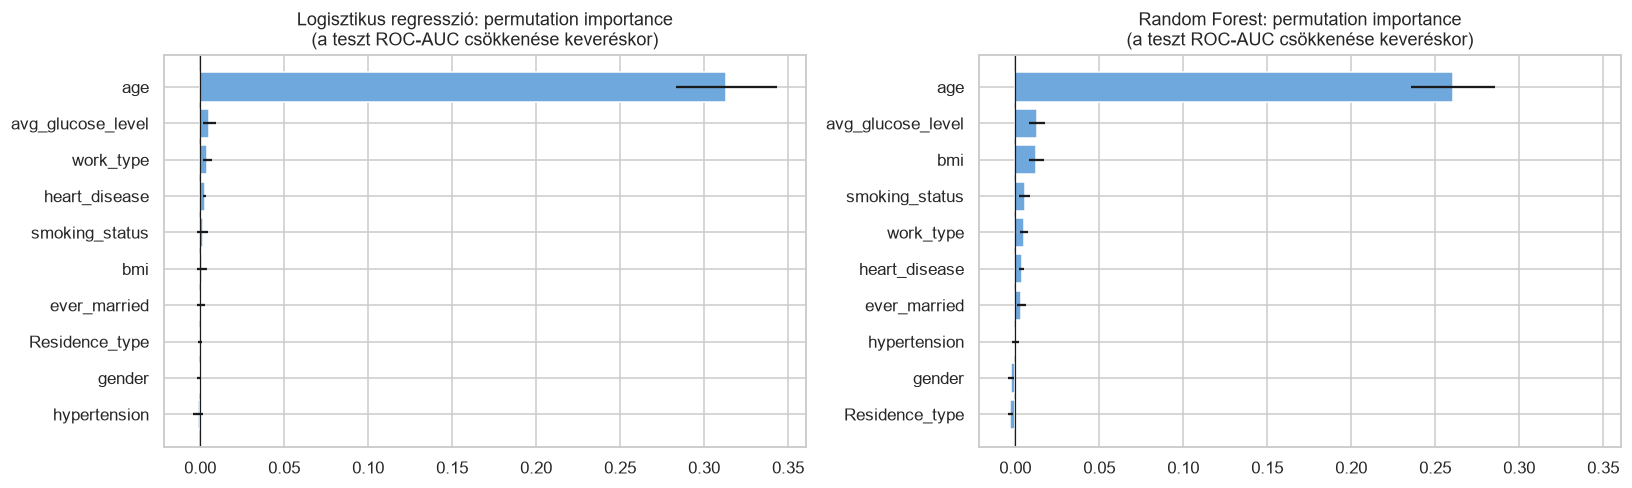

,Logisztikus regresszió,Random Forest
age,+0.3133,+0.2607
avg_glucose_level,+0.0055,+0.0130
bmi,+0.0011,+0.0125
smoking_status,+0.0014,+0.0055
work_type,+0.0043,+0.0052
heart_disease,+0.0027,+0.0037
ever_married,+0.0004,+0.0035
hypertension,-0.0013,-0.0001
gender,-0.0007,-0.0025
Residence_type,-0.0001,-0.0030


In [22]:
perm = {}
for name in [BASE, ADV]:
    r = permutation_importance(final[name], X_test, y_test, scoring="roc_auc", n_repeats=30,
                               random_state=SEED, n_jobs=-1)          # on the TEST set, on the ORIGINAL columns
    perm[name] = pd.DataFrame({"átlag": r.importances_mean, "szórás": r.importances_std},
                              index=X_test.columns).sort_values("átlag")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), sharex=True)
for a_, name in zip(ax, [BASE, ADV]):
    t = perm[name]
    a_.barh(t.index, t["átlag"], xerr=t["szórás"], color="#6fa8dc")
    a_.axvline(0, color="k", lw=0.8)
    a_.set_title(f"{short[name]}: permutation importance\n(a teszt ROC-AUC csökkenése keveréskor)")
plt.tight_layout()
save_fig(fig, "10_permutation_importance")
importance_table = pd.concat({short[n]: perm[n]["átlag"] for n in [BASE, ADV]}, axis=1)
importance_table.sort_values("Random Forest", ascending=False).map(lambda v: f"{v:+.4f}")


**Logisztikus regresszió együtthatói:** a numerikus oszlopok standardizáltak, így az együtthatójuk az 1 szórásnyi változás hatása a log-esélyre. Az $e^{\beta}$ az esélyhányados. A One-Hot oszlopok együtthatói a kategóriák egymáshoz viszonyított hatását mutatják.

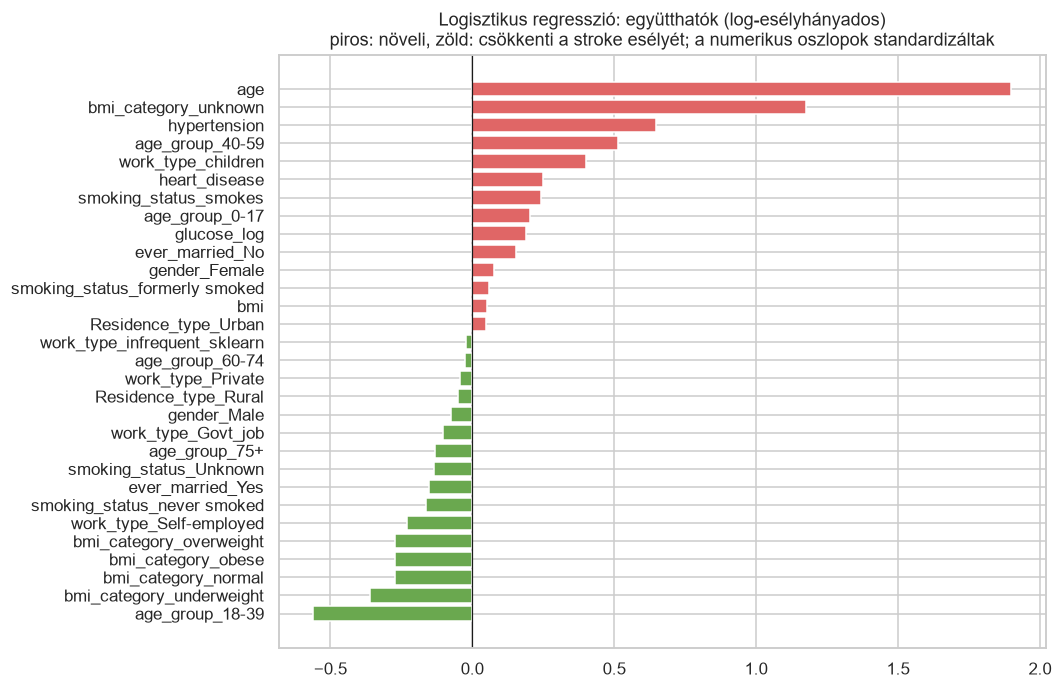

Esélyhányadosok:
  hypertension (van vs. nincs):                      1.91
  hiányzó BMI vs. normál BMI:                        4.26
  hiányzó BMI vs. túlsúly / elhízás:                 4.25 / 4.26
  age, +1 szórás (kb. 22,6 év) a korcsoporton belül: 6.67


In [23]:
lr_final = final[BASE]
coef = pd.Series(lr_final.named_steps["model"].coef_[0],
                 index=lr_final[:-1].get_feature_names_out()).sort_values()

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(coef.index, coef.values, color=np.where(coef.values > 0, "#e06666", "#6aa84f"))
ax.axvline(0, color="k", lw=0.8)
ax.set_title("Logisztikus regresszió: együtthatók (log-esélyhányados)\n"
             "piros: növeli, zöld: csökkenti a stroke esélyét; a numerikus oszlopok standardizáltak")
save_fig(fig, "11_lr_egyutthatok")
# odds ratios (OR = exp(coefficient)); the one-hot encoding keeps every category (no reference level),
# so the OR of a category is computed against another category: exp(beta_a - beta_b)
known_bmi = ["bmi_category_normal", "bmi_category_overweight", "bmi_category_obese"]
print("Esélyhányadosok:")
print(f"  hypertension (van vs. nincs):                      {np.exp(coef['hypertension']):.2f}")
print(f"  hiányzó BMI vs. normál BMI:                        {np.exp(coef['bmi_category_unknown'] - coef['bmi_category_normal']):.2f}")
print("  hiányzó BMI vs. túlsúly / elhízás:                 "
      + " / ".join(f"{np.exp(coef['bmi_category_unknown'] - coef[c]):.2f}" for c in known_bmi[1:]))
print(f"  age, +1 szórás (kb. 22,6 év) a korcsoporton belül: {np.exp(coef['age']):.2f}")


**Megfigyelések:**
- **Mindkét modell túlnyomórészt az életkorra támaszkodik.** Az `age` keverése a teszt ROC-AUC-t a logisztikus regressziónál 0,313-mal, a Random Forestnél 0,261-gyel csökkenti; minden más oszlop hatása ennek legfeljebb néhány százaléka. (Az `age` keverése a belőle számolt `age_group`-ot is érinti.) A logisztikus regresszióban az `age` lineáris tagjának esélyhányadosa 6,67 egy szórásnyi (kb. 22,6 év) növekedésre, a korcsoporton belül; a kor teljes hatását ez és az `age_group` oszlopok együtt írják le.
- **A sorrend a második helytől eltér,** de ott az értékek kicsik, és a szórásuk nagy.
  - A logisztikus regressziónál a vércukor (0,006) és a `work_type` (0,004) következik.
  - A Random Forestnél a vércukor (0,013) és a BMI (0,013) következik. Az RF ezt a két folytonos oszlopot jobban kihasználja, valószínűleg a nemlineáris küszöbök miatt.
  - A `gender` és a `Residence_type` hatása mindkét modellnél kb. 0, ahogy a 2.3 alapján várható volt.
- **A `hypertension`** esélyhányadosa 1,91: a többi jellemző rögzítése mellett magas vérnyomással kb. kétszeres a stroke esélye. A permutation importance-e mégis kb. 0 (sőt kicsit negatív). Ennek oka, hogy a magas vérnyomás korrelál a korral (ρ = 0,28), így ha összekeverjük, a modell a kor alapján nagyrészt ugyanazt a rangsort adja. Az esélyhányados a *feltételes* hatást méri, a permutation importance pedig azt, mennyi *pótolhatatlan* információt ad az oszlop a teszt-rangsoroláshoz.
- **A hiányzó BMI** esélyhányadosa a normál, a túlsúlyos és az elhízott BMI-kategóriához képest is kb. 4,3 (4,26 / 4,25 / 4,26): a többi jellemző rögzítése mellett is kb. négyszeres stroke-eséllyel jár. A One-Hot kódolás nem hagy el referenciakategóriát, ezért ezt két kategória együtthatójának különbségéből számoljuk: $e^{\beta_{unknown} - \beta_{normal}}$. Ez megerősíti a 2.4 fejezet megfigyelését (a hiány nem véletlen), és igazolja, hogy a hiányt külön kategóriaként tartottuk meg.
- **Ellentmondásosnak tűnő előjelek:** a One-Hot együtthatók között ilyenek is vannak (pl. a `work_type_children` és az `age_group_0-17` pozitív). Ennek oka a kollinearitás: a gyerekek az `age`, az `age_group` és a `work_type` oszlopban is megjelennek, és ezek együtthatói egymást ellensúlyozzák. Az egyes dummy-együtthatók ezért önmagukban nem értelmezhetők, csak a csoportjuk együttes hatása.

**A jellemzőfontosság és az eredmények korlátai:**
1. **A fontosság nem oksági kapcsolat.** A modell azt használja, ami együtt jár a stroke-kal. Az `ever_married` vagy a `work_type` hatása például az életkoron keresztül jelenik meg; nem a házasság vagy a munka okozza a stroke-ot.
2. **Korrelált jellemzők között a fontosság megoszlik vagy eltolódik.** A permutation importance alulbecsüli azt az oszlopot, amelynek információját egy másik (itt főleg az `age`) pótolja. A keverés ráadásul valószerűtlen kombinációkat is létrehoz (pl. ötéves, házas páciens).
3. **A fontosság modellfüggő,** és függ a teszthalmaztól és a metrikától is. A két modell sorrendje a második helytől eltér, és a kis értékek szórása összemérhető magukkal az értékekkel.
4. **Kevés a pozitív eset.** A teszthalmazban csak 50 stroke van, ezért minden tesztmetrika és fontosságbecslés bizonytalan (lásd a széles CI-ket).
5. **Az adat eredete ismeretlen.** Egyetlen forrásból származik, ismeretlen gyűjtési körülmények között, és nem tudjuk, hogy a mérések (pl. BMI, vércukor) a stroke előtt vagy után készültek. Ha utána, a modell részben a stroke következményeiből „jósol”. Az eredmények ezért ellenőrzés nélkül nem általánosíthatók más populációra.
6. **A jósolt valószínűségek nem kalibráltak** a `class_weight` miatt (6.1, Brier), ezért kockázatbecslésre csak kalibráció után használhatók.

## 8. Konklúzió

1. **Feladat és adat:** a Kaggle *Stroke Prediction* adathalmazán (5 110 páciens, 10 jellemző, 4,9% stroke) bináris osztályozással jeleztem előre a stroke-ot, és egy logisztikus regressziót (Baseline) hasonlítottam össze egy Random Foresttel (haladó modell).
2. **Előkészítés:**
   - A felosztás előtt csak az `id` oszlopot és az egyetlen `gender = Other` sort dobtam el. Minden tanuló lépés (medián imputálás, levágás az 1. és 99. percentilisnél, skálázás, One-Hot kódolás) egy Pipeline-ban fut, így a keresztvalidáció szivárgásmentes.
   - A BMI hiánya nem véletlen (19,9% vs. 4,3% stroke-arány), ezért a hiányt külön kategóriaként is megőriztem.
   - Az új jellemzők (`age_group`, `bmi_category`, `glucose_log`) a CV ROC-AUC-t 0,839-ről 0,849-re javították. A jellemzőkiválasztás nem hozott érdemi javulást, a PCA rontott.
3. **Eredmények:**
   - A teszthalmazon a ROC-AUC LR 0,835 [0,776; 0,889], RF 0,833 [0,773; 0,889]; a különbség CI-je [−0,018; +0,016].
   - Az 5×2cv t-próba (p = 0,15) és F-próba (p = 0,36) sem szignifikáns.
   - A McNemar-próba szignifikáns (p ≈ 7·10⁻¹²), de ez a 0,5-ös küszöb eltérő helyéből fakad: az RF 69-cel kevesebb téves riasztást, de 4-gyel több kimaradt stroke-ot ad.
4. **Javaslat: a logisztikus regresszió.** A rangsorolásban nem rosszabb, egyszerűbb és értelmezhető (esélyhányadosok), és a 0,5-ös küszöbnél több stroke-ot talál meg (recall 0,84 vs. 0,76).
5. **Jellemzőfontosság és korlátok:** mindkét modell döntően az életkorra támaszkodik. A többi jellemző hatása kicsi, és a korral való korreláció miatt nehezen választható szét. A fontosság nem oksági, a teszthalmazban csak 50 pozitív eset van, a valószínűségek nem kalibráltak, és az adat egyetlen, ismeretlen hátterű forrásból származik.
6. **Továbblépési lehetőségek:**
   - a döntési küszöb hangolása a CV-n (`TunedThresholdClassifierCV`);
   - a valószínűségek kalibrálása (`CalibratedClassifierCV`);
   - gradient boosting modellek kipróbálása;
   - beágyazott (nested) CV a hangolás optimizmusának kiszűrésére;
   - SHAP-alapú magyarázatok.

## 9. Függelék: reprodukálhatóság

A notebook a repó gyökeréből futtatható (*Run All*). A teljes kód a fenti cellákban található.

In [24]:
results = {
    "cv": {n: {"roc_auc": float(cv_table.loc[n, "ROC-AUC átlag"]), "pr_auc": float(cv_table.loc[n, "PR-AUC átlag"]),
               "best_params": {k: (v if isinstance(v, (int, float, str)) or v is None else str(v))
                               for k, v in searches[n].best_params_.items()}} for n in searches},
    "test": {n: {k: float(v) for k, v in test_table.loc[n].items()} for n in test_table.index},
    "bootstrap_diff_ci_roc_auc": [float(v) for v in boot["ROC-AUC"]["diff"]],
    "test_5x2cv_roc_auc": {k: float(five_by_two["ROC-AUC"][k]) for k in ["t", "p_t", "F", "p_F"]},
    "mcnemar": {"chi2": float(mc_chi2), "p": float(mc_p)},
}
Path("results/metrics.json").write_text(json.dumps(results, indent=2, ensure_ascii=False), encoding="utf-8")

versions = {"Python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scipy": scipy.__version__, "scikit-learn": sklearn.__version__,
            "matplotlib": matplotlib.__version__, "seaborn": sns.__version__}
print("Csomagverziók:", versions)
print(f"Teljes futási idő: {time.time() - T_START:.0f} s   |   eredmények: results/metrics.json, ábrák: {FIG_DIR.as_posix()}/")


Csomagverziók: {'Python': '3.12.16', 'numpy': '2.5.5', 'pandas': '3.1.1', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2', 'seaborn': '0.13.2'}
Teljes futási idő: 94 s   |   eredmények: results/metrics.json, ábrák: results/figures/
